In [1]:

from pathlib import Path
import pandas as pd
import numpy as np

# -----------------------------
# 1. Configure paths
# -----------------------------
# Put this notebook in the same folder as the five CSV files,
# OR change DATA_DIR to the folder containing them.
DATA_DIR = Path.home() / "Downloads"
OUTPUT_DIR = DATA_DIR / "cleaned_output"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

FILES = {
    "transactions": DATA_DIR / "transactions.csv",
    "customers": DATA_DIR / "customers.csv",
    "products": DATA_DIR / "products.csv",
    "inventory": DATA_DIR / "inventory.csv",
    "campaigns": DATA_DIR / "campaigns.csv",
}

missing = [str(path) for path in FILES.values() if not path.exists()]
if missing:
    raise FileNotFoundError(
        "Could not find these CSV files:\n"
        + "\n".join(missing)
        + "\n\nPut all five CSVs in DATA_DIR or change DATA_DIR above."
    )

# Read IDs as strings so leading zeros are preserved.
transactions = pd.read_csv(FILES["transactions"], dtype={
    "transaction_id": "string", "customer_id": "string", "product_id": "string"
})
customers = pd.read_csv(FILES["customers"], dtype={"customer_id": "string"})
products = pd.read_csv(FILES["products"], dtype={"product_id": "string"})
inventory = pd.read_csv(FILES["inventory"], dtype={
    "inventory_record_id": "string", "product_id": "string"
})
campaigns = pd.read_csv(FILES["campaigns"], dtype={"campaign_id": "string"})

print("Loaded rows:")
for name, df in [
    ("transactions", transactions), ("customers", customers),
    ("products", products), ("inventory", inventory), ("campaigns", campaigns)
]:
    print(f"  {name:14s}: {len(df):,} rows, {len(df.columns)} columns")


Loaded rows:
  transactions  : 18,000 rows, 10 columns
  customers     : 3,000 rows, 5 columns
  products      : 250 rows, 5 columns
  inventory     : 5,000 rows, 7 columns
  campaigns     : 1,200 rows, 8 columns


In [2]:

# -----------------------------
# 2. General cleaning helpers
# -----------------------------
def clean_text_columns(df):
    """Trim whitespace from text columns without changing ID values otherwise."""
    df = df.copy()
    for col in df.select_dtypes(include=["object", "string"]).columns:
        df[col] = df[col].astype("string").str.strip()
        df[col] = df[col].replace("", pd.NA)
    return df

def parse_date(df, column, errors="coerce"):
    df = df.copy()
    df[column] = pd.to_datetime(df[column], errors=errors)
    return df

def numeric_coerce(df, columns):
    df = df.copy()
    for col in columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")
    return df

transactions = clean_text_columns(transactions)
customers = clean_text_columns(customers)
products = clean_text_columns(products)
inventory = clean_text_columns(inventory)
campaigns = clean_text_columns(campaigns)

# Remove only exact duplicate rows. We do NOT automatically remove duplicate IDs,
# because those require investigation rather than guesswork.
datasets = {
    "transactions": transactions,
    "customers": customers,
    "products": products,
    "inventory": inventory,
    "campaigns": campaigns,
}
exact_duplicate_counts = {}
for name, df in datasets.items():
    before = len(df)
    df = df.drop_duplicates().copy()
    exact_duplicate_counts[name] = before - len(df)
    datasets[name] = df

transactions = datasets["transactions"]
customers = datasets["customers"]
products = datasets["products"]
inventory = datasets["inventory"]
campaigns = datasets["campaigns"]

# Parse dates.
transactions = parse_date(transactions, "timestamp")
customers = parse_date(customers, "signup_date")
inventory = parse_date(inventory, "date")
campaigns = parse_date(campaigns, "date")

# Convert expected numeric columns safely.
transactions = numeric_coerce(transactions, ["quantity", "unit_price", "discount_pct"])
products = numeric_coerce(products, ["unit_cost", "list_price", "supplier_lead_days"])
inventory = numeric_coerce(inventory, [
    "stock_on_hand", "reorder_threshold", "stockout_flag", "supplier_delay_days"
])
campaigns = numeric_coerce(campaigns, ["spend", "impressions", "clicks", "conversions"])

print("Exact duplicate rows removed:")
for name, count in exact_duplicate_counts.items():
    print(f"  {name:14s}: {count}")


Exact duplicate rows removed:
  transactions  : 0
  customers     : 0
  products      : 0
  inventory     : 0
  campaigns     : 0


In [3]:

# -----------------------------
# 3. Audit key quality and values
# -----------------------------
def duplicate_key_report(df, key, label):
    if key not in df.columns:
        print(f"{label}: missing expected key column {key!r}")
        return
    n = int(df[key].duplicated(keep=False).sum())
    print(f"{label}: rows involved in duplicate {key} values = {n:,}")

print("Duplicate key checks:")
duplicate_key_report(transactions, "transaction_id", "transactions")
duplicate_key_report(customers, "customer_id", "customers")
duplicate_key_report(products, "product_id", "products")
duplicate_key_report(inventory, "inventory_record_id", "inventory")
duplicate_key_report(campaigns, "campaign_id", "campaigns")

# Basic invalid-value flags. Keep rows, add flags, and inspect before deciding
# whether any record should be excluded from a particular analysis.
transactions["quality_invalid_quantity"] = transactions["quantity"].isna() | (transactions["quantity"] <= 0)
transactions["quality_invalid_unit_price"] = transactions["unit_price"].isna() | (transactions["unit_price"] < 0)
transactions["quality_invalid_discount"] = transactions["discount_pct"].isna() | (transactions["discount_pct"] < 0) | (transactions["discount_pct"] > 1)
transactions["quality_invalid_timestamp"] = transactions["timestamp"].isna()

inventory["quality_invalid_stock"] = inventory["stock_on_hand"].isna() | (inventory["stock_on_hand"] < 0)
inventory["quality_invalid_threshold"] = inventory["reorder_threshold"].isna() | (inventory["reorder_threshold"] < 0)
inventory["quality_invalid_date"] = inventory["date"].isna()

campaigns["quality_clicks_gt_impressions"] = (
    campaigns["clicks"].notna() & campaigns["impressions"].notna()
    & (campaigns["clicks"] > campaigns["impressions"])
)
campaigns["quality_conversions_gt_clicks"] = (
    campaigns["conversions"].notna() & campaigns["clicks"].notna()
    & (campaigns["conversions"] > campaigns["clicks"])
)
campaigns["quality_invalid_campaign_values"] = (
    campaigns[["spend", "impressions", "clicks", "conversions"]].isna().any(axis=1)
    | (campaigns[["spend", "impressions", "clicks", "conversions"]] < 0).any(axis=1)
    | campaigns["date"].isna()
)

# Status and category values are not rewritten automatically; print them for review.
print("\nTransaction statuses:", sorted(transactions["status"].dropna().astype(str).unique()))
print("Sales channels:", sorted(transactions["channel"].dropna().astype(str).unique()))
print("Product categories:", sorted(products["category"].dropna().astype(str).unique()))

print("\nQuality flag counts:")
for col in [c for c in transactions.columns if c.startswith("quality_")]:
    print(f"  transactions.{col}: {int(transactions[col].sum()):,}")
for col in [c for c in inventory.columns if c.startswith("quality_")]:
    print(f"  inventory.{col}: {int(inventory[col].sum()):,}")
for col in [c for c in campaigns.columns if c.startswith("quality_")]:
    print(f"  campaigns.{col}: {int(campaigns[col].sum()):,}")

# Referential integrity checks.
customer_ids = set(customers["customer_id"].dropna())
product_ids = set(products["product_id"].dropna())
print("\nUnmatched transaction customer IDs:",
      int((~transactions["customer_id"].isin(customer_ids)).sum()))
print("Unmatched transaction product IDs:",
      int((~transactions["product_id"].isin(product_ids)).sum()))
print("Inventory product IDs missing from products:",
      int((~inventory["product_id"].isin(product_ids)).sum()))


Duplicate key checks:
transactions: rows involved in duplicate transaction_id values = 0
customers: rows involved in duplicate customer_id values = 0
products: rows involved in duplicate product_id values = 0
inventory: rows involved in duplicate inventory_record_id values = 0
campaigns: rows involved in duplicate campaign_id values = 0

Transaction statuses: ['Cancelled', 'Completed', 'Pending', 'Returned']
Sales channels: ['App', 'Store', 'Web']
Product categories: ['Beauty', 'Electronics', 'Fashion', 'Grocery', 'Home', 'Sports']

Quality flag counts:
  transactions.quality_invalid_quantity: 0
  transactions.quality_invalid_unit_price: 0
  transactions.quality_invalid_discount: 0
  transactions.quality_invalid_timestamp: 0
  inventory.quality_invalid_stock: 0
  inventory.quality_invalid_threshold: 0
  inventory.quality_invalid_date: 0
  campaigns.quality_clicks_gt_impressions: 84
  campaigns.quality_conversions_gt_clicks: 88
  campaigns.quality_invalid_campaign_values: 0

Unmatched t

In [4]:

# -----------------------------
# 4. Clean master tables and deduplicate inventory snapshots
# -----------------------------
# For master tables, keep the first row for duplicate IDs but write duplicates
# to the audit report. For a serious project, review these rows manually first.
customers_duplicate_ids = customers[customers["customer_id"].duplicated(keep=False)].copy()
products_duplicate_ids = products[products["product_id"].duplicated(keep=False)].copy()

customers_clean = customers.drop_duplicates(subset=["customer_id"], keep="first").copy()
products_clean = products.drop_duplicates(subset=["product_id"], keep="first").copy()

# Inventory can have several records for the same product/date.
# We aggregate those records rather than arbitrarily selecting a row:
# - median stock and supplier delay
# - maximum reorder threshold
# - maximum stockout flag
# - count of source records
# This is a documented compromise. Review duplicate groups if conflicting records
# matter to your business use case.
inventory_valid_dates = inventory[inventory["date"].notna()].copy()
inventory_daily = (
    inventory_valid_dates
    .groupby(["product_id", "date"], as_index=False, dropna=False)
    .agg(
        stock_on_hand=("stock_on_hand", "median"),
        reorder_threshold=("reorder_threshold", "max"),
        stockout_flag=("stockout_flag", "max"),
        supplier_delay_days=("supplier_delay_days", "median"),
        inventory_source_rows=("inventory_record_id", "size"),
        inventory_record_ids=("inventory_record_id", lambda s: " | ".join(s.dropna().astype(str)))
    )
)
inventory_daily["inventory_duplicate_date_group"] = inventory_daily["inventory_source_rows"] > 1
inventory_daily["inventory_below_reorder_threshold"] = (
    inventory_daily["stock_on_hand"].notna()
    & inventory_daily["reorder_threshold"].notna()
    & (inventory_daily["stock_on_hand"] <= inventory_daily["reorder_threshold"])
)

# Join transactions to customer and product master data.
# Validate many-to-one joins so duplicate master IDs cannot multiply transactions.
tx = transactions.merge(
    customers_clean, on="customer_id", how="left", validate="many_to_one",
    suffixes=("", "_customer")
)
tx = tx.merge(
    products_clean, on="product_id", how="left", validate="many_to_one",
    suffixes=("", "_product")
)

# Create a candidate discounted line value. Confirm the meaning of unit_price and
# discount_pct before treating this as official revenue.
tx["gross_line_value"] = tx["quantity"] * tx["unit_price"]
tx["estimated_discount_value"] = tx["gross_line_value"] * tx["discount_pct"]
tx["estimated_discounted_line_value"] = (
    tx["gross_line_value"] * (1 - tx["discount_pct"])
)
tx["estimated_line_cost"] = tx["quantity"] * tx["unit_cost"]
tx["estimated_line_margin_before_returns"] = (
    tx["estimated_discounted_line_value"] - tx["estimated_line_cost"]
)

# As-of join: attach the latest inventory snapshot on or before the transaction
# timestamp, for the same product. This does NOT mean inventory was continuously
# observed between dates. The age column helps identify stale snapshots.
tx = tx[tx["timestamp"].notna()].copy()
tx["transaction_date"] = tx["timestamp"].dt.normalize()
inventory_for_join = inventory_daily.rename(columns={"date": "inventory_date"}).copy()

tx_sorted = tx.sort_values(["timestamp", "product_id"]).copy()
inv_sorted = inventory_for_join.sort_values(["inventory_date", "product_id"]).copy()

# merge_asof requires sorting on the as-of key. Sorting globally by the date/time
# first, then by product, satisfies pandas' ordering requirement.
tx_sorted = tx.sort_values(["timestamp", "product_id"]).copy()
inv_sorted = inventory_for_join.sort_values(["inventory_date", "product_id"]).copy()

master = pd.merge_asof(
    tx_sorted,
    inv_sorted,
    left_on="timestamp",
    right_on="inventory_date",
    by="product_id",
    direction="backward",
    allow_exact_matches=True
)
master["inventory_snapshot_age_days"] = (
    master["timestamp"].dt.normalize() - master["inventory_date"]
).dt.days
master["inventory_snapshot_stale_over_30_days"] = (
    master["inventory_snapshot_age_days"].notna()
    & (master["inventory_snapshot_age_days"] > 30)
)

print("Transaction rows before joins:", len(transactions))
print("Transaction rows in master:", len(master))
print("Master row count preserved:", len(master) == int(transactions["timestamp"].notna().sum()))


Transaction rows before joins: 18000
Transaction rows in master: 18000
Master row count preserved: True


In [5]:

# -----------------------------
# 5. Save outputs
# -----------------------------
master_path = OUTPUT_DIR / "retail_master_transactions.csv"
master.to_csv(master_path, index=False)

customers_clean.to_csv(OUTPUT_DIR / "customers_clean.csv", index=False)
products_clean.to_csv(OUTPUT_DIR / "products_clean.csv", index=False)
inventory_daily.to_csv(OUTPUT_DIR / "inventory_daily_clean.csv", index=False)
campaigns.to_csv(
    OUTPUT_DIR / "campaigns_clean_with_quality_flags.csv",
    index=False
)

# Save records requiring manual review
customers_duplicate_ids.to_csv(
    OUTPUT_DIR / "review_duplicate_customer_ids.csv", index=False
)
products_duplicate_ids.to_csv(
    OUTPUT_DIR / "review_duplicate_product_ids.csv", index=False
)

inventory[
    inventory.duplicated(["product_id", "date"], keep=False)
].to_csv(
    OUTPUT_DIR / "review_duplicate_inventory_product_dates.csv",
    index=False
)

campaigns[
    campaigns["quality_clicks_gt_impressions"]
    | campaigns["quality_conversions_gt_clicks"]
].to_csv(
    OUTPUT_DIR / "review_campaign_metric_anomalies.csv",
    index=False
)

# Create audit summary
audit_rows = []

for name, df in [
    ("transactions_cleaned", transactions),
    ("customers_cleaned", customers_clean),
    ("products_cleaned", products_clean),
    ("inventory_daily_cleaned", inventory_daily),
    ("campaigns_with_flags", campaigns),
    ("master_transactions", master),
]:
    audit_rows.append({
        "dataset": name,
        "rows": len(df),
        "columns": len(df.columns),
        "missing_cells": int(df.isna().sum().sum()),
    })

# Save audit report
pd.DataFrame(audit_rows).to_csv(
    OUTPUT_DIR / "audit_summary.csv",
    index=False
)

# Final confirmation
print("\nFinished. Outputs saved to:", OUTPUT_DIR.resolve())
print("Main combined CSV:", master_path.resolve())

print("\nImportant:")
print("- Campaigns remain separate because transactions have no campaign_id.")
print("- Inventory columns are the latest available snapshot on/before each transaction.")
print("- Check inventory_snapshot_age_days before interpreting attached stock as current.")
print("- Estimated revenue/margin fields need confirmation against the data definitions.")



Finished. Outputs saved to: C:\Users\adria\Downloads\cleaned_output
Main combined CSV: C:\Users\adria\Downloads\cleaned_output\retail_master_transactions.csv

Important:
- Campaigns remain separate because transactions have no campaign_id.
- Inventory columns are the latest available snapshot on/before each transaction.
- Check inventory_snapshot_age_days before interpreting attached stock as current.
- Estimated revenue/margin fields need confirmation against the data definitions.


In [6]:

import pandas as pd
from pathlib import Path

DATA_DIR = Path.home() / "Downloads" / "cleaned_output"

# Reload the combined dataset
df = pd.read_csv(
    DATA_DIR / "retail_master_transactions.csv",
    low_memory=False
)

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst five rows:")
display(df.head())

# Inspect the two columns that triggered the warning
for col in [
    "inventory_duplicate_date_group",
    "inventory_below_reorder_threshold"
]:
    if col in df.columns:
        print(f"\n{col}")
        print("Data type:", df[col].dtype)
        print(df[col].value_counts(dropna=False).head(10))


Dataset shape: (18000, 39)

Column names:
['transaction_id', 'customer_id', 'product_id', 'timestamp', 'quantity', 'unit_price', 'discount_pct', 'status', 'channel', 'payment_method', 'quality_invalid_quantity', 'quality_invalid_unit_price', 'quality_invalid_discount', 'quality_invalid_timestamp', 'region', 'customer_segment', 'signup_date', 'preferred_channel', 'category', 'unit_cost', 'list_price', 'supplier_lead_days', 'gross_line_value', 'estimated_discount_value', 'estimated_discounted_line_value', 'estimated_line_cost', 'estimated_line_margin_before_returns', 'transaction_date', 'inventory_date', 'stock_on_hand', 'reorder_threshold', 'stockout_flag', 'supplier_delay_days', 'inventory_source_rows', 'inventory_record_ids', 'inventory_duplicate_date_group', 'inventory_below_reorder_threshold', 'inventory_snapshot_age_days', 'inventory_snapshot_stale_over_30_days']

First five rows:


,transaction_id,customer_id,product_id,timestamp,quantity,unit_price,discount_pct,status,channel,payment_method,...,stock_on_hand,reorder_threshold,stockout_flag,supplier_delay_days,inventory_source_rows,inventory_record_ids,inventory_duplicate_date_group,inventory_below_reorder_threshold,inventory_snapshot_age_days,inventory_snapshot_stale_over_30_days
0,TX015710,CU00849,PR0198,2025-01-01 00:11:00,1,320.96,0.10,Completed,Web,UPI,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False
1,TX009958,CU02489,PR0050,2025-01-01 00:45:00,3,161.35,0.25,Cancelled,App,NetBanking,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False
2,TX010201,CU02234,PR0247,2025-01-01 01:36:00,4,355.48,0.00,Cancelled,App,Cash,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False
3,TX003234,CU02435,PR0230,2025-01-01 01:55:00,3,240.79,0.15,Completed,Web,Card,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False
4,TX004197,CU00570,PR0179,2025-01-01 02:04:00,5,350.06,0.05,Completed,Web,Card,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False



inventory_duplicate_date_group
Data type: object
inventory_duplicate_date_group
False    16758
NaN        876
True       366
Name: count, dtype: int64

inventory_below_reorder_threshold
Data type: object
inventory_below_reorder_threshold
False    14706
True      2418
NaN        876
Name: count, dtype: int64


In [7]:

# -----------------------------
# 7. Validate the final dataset
# -----------------------------

print("=" * 50)
print("FINAL DATASET VALIDATION")
print("=" * 50)

# 1. Dataset dimensions
print("\n1. Dataset dimensions")
print("Rows:", f"{len(df):,}")
print("Columns:", len(df.columns))

# 2. Duplicate transaction IDs
print("\n2. Duplicate transaction IDs")
if "transaction_id" in df.columns:
    print(
        "Duplicate transaction IDs:",
        int(df["transaction_id"].duplicated().sum())
    )

# 3. Missing values
print("\n3. Columns with missing values")
missing = df.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False)

if missing.empty:
    print("No missing values found.")
else:
    print(missing.head(20))

# 4. Check transaction dates
print("\n4. Transaction date range")
if "timestamp" in df.columns:
    dates = pd.to_datetime(df["timestamp"], errors="coerce")
    print("Earliest:", dates.min())
    print("Latest:  ", dates.max())
    print("Invalid dates:", int(dates.isna().sum()))

# 5. Check estimated sales and margin
print("\n5. Sales and margin summary")
for col in [
    "gross_line_value",
    "estimated_discounted_line_value",
    "estimated_line_cost",
    "estimated_line_margin_before_returns"
]:
    if col in df.columns:
        print(f"\n{col}")
        print(df[col].describe().round(2))

# 6. Check inventory matching
print("\n6. Inventory snapshot availability")
if "inventory_date" in df.columns:
    print(
        "Transactions with an inventory snapshot:",
        f"{df['inventory_date'].notna().sum():,}"
    )
    print(
        "Transactions without an inventory snapshot:",
        f"{df['inventory_date'].isna().sum():,}"
    )

# 7. Check data-quality flags
print("\n7. Data-quality flags")
quality_cols = [
    col for col in df.columns
    if col.startswith("quality_")
]

for col in quality_cols:
    print(f"{col}: {int(df[col].fillna(False).sum()):,}")

print("\nValidation completed.")


FINAL DATASET VALIDATION

1. Dataset dimensions
Rows: 18,000
Columns: 39

2. Duplicate transaction IDs
Duplicate transaction IDs: 0

3. Columns with missing values
inventory_date                       876
stock_on_hand                        876
reorder_threshold                    876
stockout_flag                        876
supplier_delay_days                  876
inventory_source_rows                876
inventory_record_ids                 876
inventory_duplicate_date_group       876
inventory_below_reorder_threshold    876
inventory_snapshot_age_days          876
dtype: int64

4. Transaction date range
Earliest: 2025-01-01 00:11:00
Latest:   2025-12-31 23:53:00
Invalid dates: 0

5. Sales and margin summary

gross_line_value
count    18000.00
mean       564.68
std        446.92
min          6.28
25%        208.33
50%        443.76
75%        836.90
max       1997.10
Name: gross_line_value, dtype: float64

estimated_discounted_line_value
count    18000.00
mean       521.71
std       

OVERALL SALES PERFORMANCE
Transaction lines: 18,000
Estimated sales: 9390803.1
Estimated margin: 2539030.63
Average estimated sales per line: 521.71
Negative-margin lines: 6829

MONTHLY SALES SUMMARY


,month,estimated_sales,estimated_margin,transaction_lines
0,2025-01,810971.04,230201.28,1545
1,2025-02,723896.67,181401.19,1380
2,2025-03,817332.54,232882.89,1557
3,2025-04,726300.64,177465.72,1446
4,2025-05,861595.77,251290.79,1603
5,2025-06,749786.98,206795.73,1431
6,2025-07,845269.83,220664.81,1557
7,2025-08,787984.78,202182.98,1560
8,2025-09,781736.91,210637.10,1502
9,2025-10,765979.25,204073.37,1460


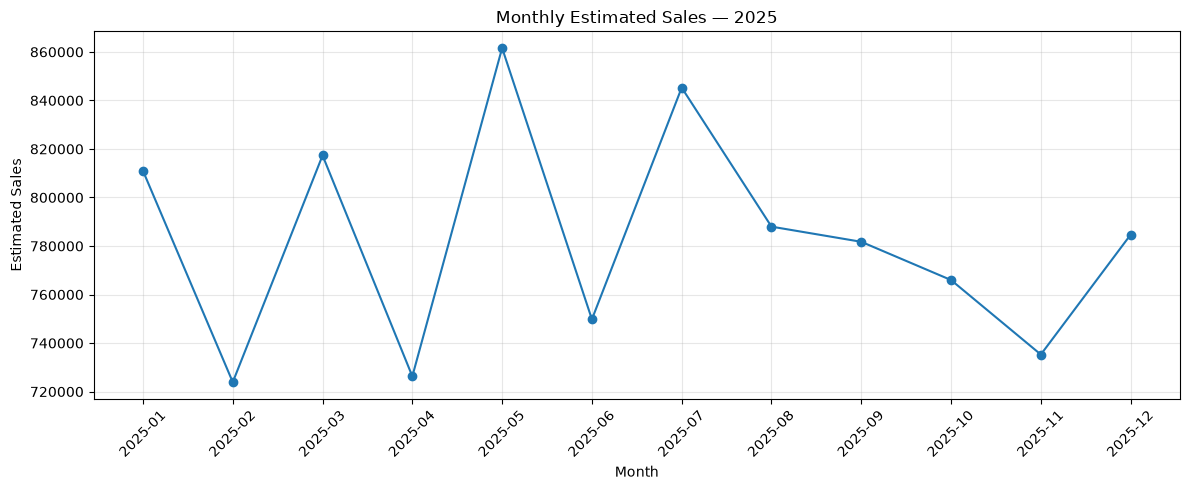


CATEGORY PERFORMANCE


,category,estimated_sales,estimated_margin,transaction_lines
0,Home,1801235.99,562841.57,3141
1,Electronics,1692149.24,525617.04,3286
2,Sports,1666155.45,498419.02,3041
3,Grocery,1655754.72,402579.82,3150
4,Fashion,1377694.92,480517.15,2598
5,Beauty,1197812.78,69056.02,2784



TOP 10 PRODUCTS BY ESTIMATED SALES


,product_id,estimated_sales,estimated_margin,units_sold
0,PR0127,86546.29,17806.29,280
1,PR0022,85578.32,57655.40,268
2,PR0193,83386.13,31434.08,261
3,PR0097,83303.32,57083.08,244
4,PR0185,82317.60,33756.78,253
5,PR0146,80210.45,71454.85,280
6,PR0120,80078.15,49301.05,265
7,PR0220,79411.73,17304.23,250
8,PR0065,78351.79,44736.79,270
9,PR0082,75277.01,38899.61,228



SALES CHANNEL PERFORMANCE


,channel,estimated_sales,estimated_margin,transaction_lines
0,Web,4240209.24,1155871.57,8092
1,App,3671332.69,955258.03,7115
2,Store,1479261.16,427901.02,2793



TRANSACTION STATUS BREAKDOWN


,status,row_count
0,Completed,13962
1,Cancelled,1689
2,Returned,1431
3,Pending,918



EDA step completed.


In [8]:

# -----------------------------
# 8. Exploratory Data Analysis
# -----------------------------

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Work on a copy so the original dataset remains unchanged
eda = df.copy()

eda["timestamp"] = pd.to_datetime(
    eda["timestamp"], errors="coerce"
)

# Choose the available sales and margin columns
sales_col = "estimated_discounted_line_value"
margin_col = "estimated_line_margin_before_returns"

# Identify available descriptive columns
product_col = next(
    (c for c in ["product_name", "product_id"] if c in eda.columns),
    None
)

category_col = next(
    (c for c in ["category", "product_category"] if c in eda.columns),
    None
)

channel_col = "channel" if "channel" in eda.columns else None
status_col = "status" if "status" in eda.columns else None

# -----------------------------
# 1. Overall sales performance
# -----------------------------

print("=" * 55)
print("OVERALL SALES PERFORMANCE")
print("=" * 55)

print("Transaction lines:", f"{len(eda):,}")
print(
    "Estimated sales:",
    round(eda[sales_col].sum(), 2)
)
print(
    "Estimated margin:",
    round(eda[margin_col].sum(), 2)
)
print(
    "Average estimated sales per line:",
    round(eda[sales_col].mean(), 2)
)
print(
    "Negative-margin lines:",
    int((eda[margin_col] < 0).sum())
)

# -----------------------------
# 2. Monthly sales trend
# -----------------------------

eda["month"] = eda["timestamp"].dt.to_period("M").astype("string")

monthly_sales = (
    eda.dropna(subset=["timestamp"])
    .groupby("month", as_index=False)
    .agg(
        estimated_sales=(sales_col, "sum"),
        estimated_margin=(margin_col, "sum"),
        transaction_lines=("transaction_id", "nunique")
    )
)

print("\nMONTHLY SALES SUMMARY")
display(monthly_sales.round(2))

plt.figure(figsize=(12, 5))
plt.plot(
    monthly_sales["month"],
    monthly_sales["estimated_sales"],
    marker="o"
)
plt.title("Monthly Estimated Sales — 2025")
plt.xlabel("Month")
plt.ylabel("Estimated Sales")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# -----------------------------
# 3. Category performance
# -----------------------------

if category_col:
    category_sales = (
        eda.groupby(category_col, dropna=False)
        .agg(
            estimated_sales=(sales_col, "sum"),
            estimated_margin=(margin_col, "sum"),
            transaction_lines=("transaction_id", "nunique")
        )
        .sort_values("estimated_sales", ascending=False)
        .reset_index()
    )

    print("\nCATEGORY PERFORMANCE")
    display(category_sales.round(2))
else:
    print("\nNo recognized product category column found.")

# -----------------------------
# 4. Top 10 products
# -----------------------------

if product_col:
    top_products = (
        eda.groupby(product_col, dropna=False)
        .agg(
            estimated_sales=(sales_col, "sum"),
            estimated_margin=(margin_col, "sum"),
            units_sold=("quantity", "sum")
        )
        .sort_values("estimated_sales", ascending=False)
        .head(10)
        .reset_index()
    )

    print("\nTOP 10 PRODUCTS BY ESTIMATED SALES")
    display(top_products.round(2))
else:
    print("\nNo recognized product identifier column found.")

# -----------------------------
# 5. Sales channel performance
# -----------------------------

if channel_col:
    channel_sales = (
        eda.groupby(channel_col, dropna=False)
        .agg(
            estimated_sales=(sales_col, "sum"),
            estimated_margin=(margin_col, "sum"),
            transaction_lines=("transaction_id", "nunique")
        )
        .sort_values("estimated_sales", ascending=False)
        .reset_index()
    )

    print("\nSALES CHANNEL PERFORMANCE")
    display(channel_sales.round(2))

# -----------------------------
# 6. Transaction status breakdown
# -----------------------------

if status_col:
    print("\nTRANSACTION STATUS BREAKDOWN")
    display(
        eda[status_col]
        .value_counts(dropna=False)
        .rename_axis("status")
        .reset_index(name="row_count")
    )

print("\nEDA step completed.")


In [9]:

# -----------------------------
# 9. Completed Transaction Analysis
# -----------------------------

# Filter completed transactions without modifying df
completed = df[
    df["status"].astype("string").str.strip().str.lower()
    == "completed"
].copy()

sales_col = "estimated_discounted_line_value"
margin_col = "estimated_line_margin_before_returns"

print("=" * 55)
print("COMPLETED TRANSACTION ANALYSIS")
print("=" * 55)

# 1. Overall completed transaction performance
print("\n1. Completed transaction summary")
print("Completed lines:", f"{len(completed):,}")
print("Estimated sales:", round(completed[sales_col].sum(), 2))
print("Estimated margin:", round(completed[margin_col].sum(), 2))

if completed[sales_col].sum() != 0:
    print(
        "Estimated margin / sales (%):",
        round(
            completed[margin_col].sum()
            / completed[sales_col].sum() * 100,
            2
        )
    )

print(
    "Negative-margin lines:",
    int((completed[margin_col] < 0).sum())
)

# 2. Category performance
if "category" in completed.columns:
    category_results = (
        completed.groupby("category", dropna=False)
        .agg(
            estimated_sales=(sales_col, "sum"),
            estimated_margin=(margin_col, "sum"),
            lines=("transaction_id", "nunique")
        )
        .sort_values("estimated_sales", ascending=False)
        .reset_index()
    )

    category_results["margin_pct"] = (
        category_results["estimated_margin"]
        / category_results["estimated_sales"].replace(0, float("nan"))
        * 100
    )

    print("\n2. Completed sales by category")
    display(category_results.round(2))

# 3. Channel performance
if "channel" in completed.columns:
    channel_results = (
        completed.groupby("channel", dropna=False)
        .agg(
            estimated_sales=(sales_col, "sum"),
            estimated_margin=(margin_col, "sum"),
            lines=("transaction_id", "nunique")
        )
        .sort_values("estimated_sales", ascending=False)
        .reset_index()
    )

    channel_results["margin_pct"] = (
        channel_results["estimated_margin"]
        / channel_results["estimated_sales"].replace(0, float("nan"))
        * 100
    )

    print("\n3. Completed sales by channel")
    display(channel_results.round(2))

# 4. Negative-margin investigation
negative_margin = completed[
    completed[margin_col] < 0
].copy()

print("\n4. Negative-margin completed lines")
print("Count:", f"{len(negative_margin):,}")

if len(negative_margin) > 0:
    print(
        "Total estimated negative margin:",
        round(negative_margin[margin_col].sum(), 2)
    )

    if "category" in negative_margin.columns:
        print("\nNegative-margin lines by category:")
        display(
            negative_margin.groupby("category")
            .agg(
                negative_margin_lines=(margin_col, "size"),
                estimated_margin=(margin_col, "sum")
            )
            .sort_values("estimated_margin")
            .round(2)
        )

print("\nCompleted transaction analysis finished.")


COMPLETED TRANSACTION ANALYSIS

1. Completed transaction summary
Completed lines: 13,962
Estimated sales: 7301698.25
Estimated margin: 1968988.4
Estimated margin / sales (%): 26.97
Negative-margin lines: 5315

2. Completed sales by category


,category,estimated_sales,estimated_margin,lines,margin_pct
0,Home,1390889.32,431659.48,2436,31.03
1,Electronics,1316100.72,412263.67,2535,31.32
2,Sports,1301361.92,378860.24,2374,29.11
3,Grocery,1282925.56,300332.44,2437,23.41
4,Fashion,1076686.47,379136.86,2016,35.21
5,Beauty,933734.26,66735.71,2164,7.15



3. Completed sales by channel


,channel,estimated_sales,estimated_margin,lines,margin_pct
0,Web,3320492.10,895102.99,6296,26.96
1,App,2829459.48,742581.55,5499,26.24
2,Store,1151746.67,331303.86,2167,28.77



4. Negative-margin completed lines
Count: 5,315
Total estimated negative margin: -1214115.5

Negative-margin lines by category:


,negative_margin_lines,estimated_margin
category,,
Beauty,1187,-309096.42
Grocery,997,-246611.86
Electronics,952,-184366.60
Home,807,-179804.98
Sports,696,-155494.27
Fashion,676,-138741.37



Completed transaction analysis finished.


In [10]:

# -----------------------------
# Investigate Negative Margins
# -----------------------------

# Use completed transactions only
completed = df[
    df["status"].astype("string").str.strip().str.lower()
    == "completed"
].copy()

margin_col = "estimated_line_margin_before_returns"

negative = completed[completed[margin_col] < 0].copy()

print("Completed transaction lines:", len(completed))
print("Negative-margin completed lines:", len(negative))

print(
    "Percentage with negative margin:",
    round(len(negative) / len(completed) * 100, 2),
    "%"
)

# 1. Inspect example records
columns_to_show = [
    c for c in [
        "transaction_id",
        "product_id",
        "category",
        "quantity",
        "unit_price",
        "discount_pct",
        "unit_cost",
        "gross_line_value",
        "estimated_discounted_line_value",
        margin_col,
    ]
    if c in negative.columns
]

print("\nExample negative-margin records:")
display(negative[columns_to_show].head(15))

# 2. Negative-margin lines by category
if "category" in negative.columns:
    print("\nNegative-margin lines by category:")
    display(
        negative.groupby("category")
        .agg(
            negative_lines=(margin_col, "size"),
            total_negative_margin=(margin_col, "sum"),
            average_negative_margin=(margin_col, "mean")
        )
        .sort_values("total_negative_margin")
        .round(2)
    )

# 3. Compare discounts on negative vs non-negative lines
print("\nDiscount comparison:")
if "discount_pct" in completed.columns:
    completed["margin_group"] = (
        completed[margin_col] < 0
    ).map({
        True: "Negative margin",
        False: "Zero or positive margin"
    })

    display(
        completed.groupby("margin_group", dropna=False)
        .agg(
            lines=(margin_col, "size"),
            average_discount=("discount_pct", "mean"),
            average_unit_price=("unit_price", "mean"),
            average_unit_cost=("unit_cost", "mean"),
            average_margin=(margin_col, "mean")
        )
        .round(3)
    )

print("\nInvestigation complete.")


Completed transaction lines: 13962
Negative-margin completed lines: 5315
Percentage with negative margin: 38.07 %

Example negative-margin records:


,transaction_id,product_id,category,quantity,unit_price,discount_pct,unit_cost,gross_line_value,estimated_discounted_line_value,estimated_line_margin_before_returns
5,TX002062,PR0004,Sports,4,40.94,0.05,88.98,163.76,155.5720,-200.3480
7,TX011958,PR0158,Electronics,3,60.98,0.00,196.78,182.94,182.9400,-407.4000
10,TX001744,PR0247,Sports,2,284.38,0.20,243.07,568.76,455.0080,-31.1320
14,TX008175,PR0008,Beauty,5,30.55,0.15,81.30,152.75,129.8375,-276.6625
18,TX010647,PR0057,Beauty,1,75.51,0.05,129.07,75.51,71.7345,-57.3355
21,TX011493,PR0124,Sports,5,210.78,0.15,223.58,1053.90,895.8150,-222.0850
25,TX016311,PR0172,Home,4,185.34,0.05,207.02,741.36,704.2920,-123.7880
28,TX015197,PR0013,Home,4,174.68,0.15,191.21,698.72,593.9120,-170.9280
30,TX001663,PR0052,Grocery,1,96.02,0.15,155.43,96.02,81.6170,-73.8130
42,TX010428,PR0211,Fashion,3,27.79,0.15,125.04,83.37,70.8645,-304.2555



Negative-margin lines by category:


,negative_lines,total_negative_margin,average_negative_margin
category,,,
Beauty,1187,-309096.42,-260.40
Grocery,997,-246611.86,-247.35
Electronics,952,-184366.60,-193.66
Home,807,-179804.98,-222.81
Sports,696,-155494.27,-223.41
Fashion,676,-138741.37,-205.24



Discount comparison:


,lines,average_discount,average_unit_price,average_unit_cost,average_margin
margin_group,,,,,
Negative margin,5315,0.100,94.863,159.675,-228.432
Zero or positive margin,8647,0.074,246.027,106.120,368.117



Investigation complete.


In [13]:

# ==========================================
# STEP 9: FINANCIAL METRICS BY STATUS
# ==========================================

# Standardize transaction status labels
df["status_clean"] = (
    df["status"]
    .astype("string")
    .str.strip()
    .str.title()
)

# Create a flag for negative-margin transaction lines
df["is_negative_margin"] = (
    df["estimated_line_margin_before_returns"] < 0
)

# Summarize metrics by transaction status
status_summary = (
    df.groupby("status_clean", dropna=False)
    .agg(
        transaction_lines=("transaction_id", "size"),
        estimated_sales=("estimated_discounted_line_value", "sum"),
        estimated_margin=(
            "estimated_line_margin_before_returns", "sum"
        ),
        average_line_sales=(
            "estimated_discounted_line_value", "mean"
        ),
        negative_margin_lines=("is_negative_margin", "sum")
    )
    .round(2)
)

print("Financial metrics by transaction status:")
display(status_summary)

print("\nTransaction status counts:")
display(df["status_clean"].value_counts(dropna=False))


Financial metrics by transaction status:


,transaction_lines,estimated_sales,estimated_margin,average_line_sales,negative_margin_lines
status_clean,,,,,
Cancelled,1689,861849.61,221336.47,510.27,657
Completed,13962,7301698.25,1968988.40,522.97,5315
Pending,918,466932.94,122588.53,508.64,340
Returned,1431,760322.30,226117.23,531.32,517



Transaction status counts:


status_clean
Completed    13962
Cancelled     1689
Returned      1431
Pending        918
Name: count, dtype: int64[pyarrow]

MONTHLY COMPLETED-TRANSACTION ANALYSIS


,estimated_sales,estimated_margin,transaction_lines
month,,,
2025-01,631337.30,178488.70,1201
2025-02,559526.43,142395.76,1064
2025-03,633536.51,179674.60,1214
2025-04,563229.75,138029.40,1121
2025-05,679623.53,199515.32,1251
2025-06,589542.17,168292.92,1122
2025-07,663235.42,165097.48,1208
2025-08,615662.18,154446.27,1216
2025-09,594603.85,156755.69,1150



CATEGORY PERFORMANCE — COMPLETED TRANSACTIONS


,estimated_sales,estimated_margin,transaction_lines
category,,,
Home,1390889.32,431659.48,2436
Electronics,1316100.72,412263.67,2535
Sports,1301361.92,378860.24,2374
Grocery,1282925.56,300332.44,2437
Fashion,1076686.47,379136.86,2016
Beauty,933734.26,66735.71,2164


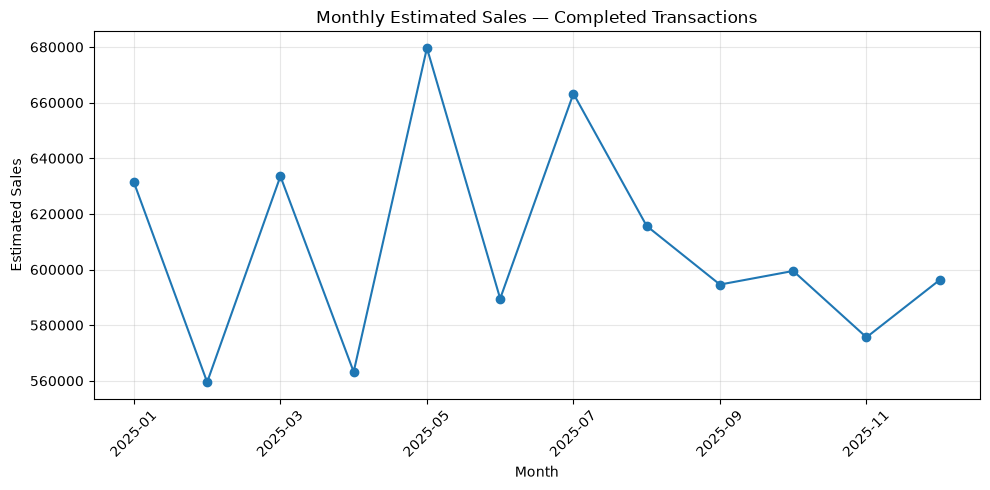

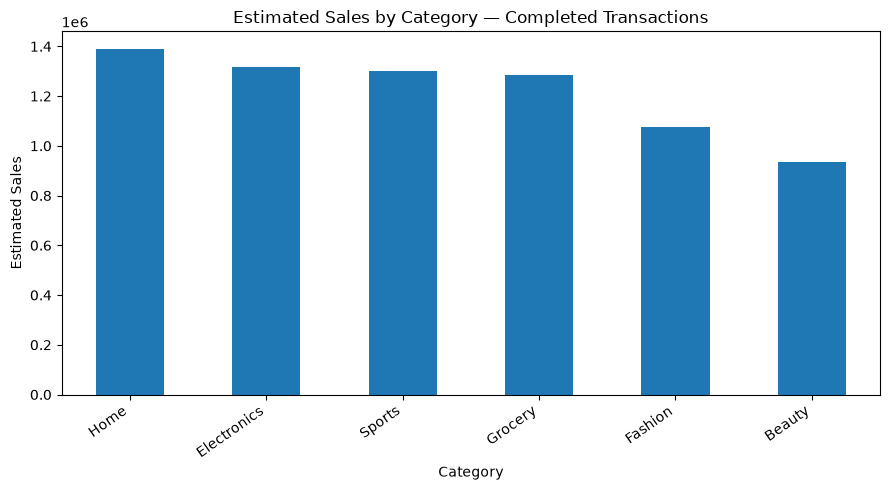


Completed-sales analysis finished.


In [14]:

# ==========================================
# STEP 10: COMPLETED SALES ANALYSIS
# ==========================================

import pandas as pd
import matplotlib.pyplot as plt

# Keep completed transactions for preliminary sales analysis
completed_df = df[
    df["status_clean"].eq("Completed")
].copy()

# Ensure transaction timestamps are datetime values
completed_df["timestamp"] = pd.to_datetime(
    completed_df["timestamp"], errors="coerce"
)

# Create monthly sales summary
completed_df["month"] = (
    completed_df["timestamp"].dt.to_period("M").astype(str)
)

monthly_summary = (
    completed_df.groupby("month")
    .agg(
        estimated_sales=("estimated_discounted_line_value", "sum"),
        estimated_margin=(
            "estimated_line_margin_before_returns", "sum"
        ),
        transaction_lines=("transaction_id", "size")
    )
    .round(2)
)

print("MONTHLY COMPLETED-TRANSACTION ANALYSIS")
display(monthly_summary)

# Create category sales summary
category_summary = (
    completed_df.groupby("category")
    .agg(
        estimated_sales=("estimated_discounted_line_value", "sum"),
        estimated_margin=(
            "estimated_line_margin_before_returns", "sum"
        ),
        transaction_lines=("transaction_id", "size")
    )
    .sort_values("estimated_sales", ascending=False)
    .round(2)
)

print("\nCATEGORY PERFORMANCE — COMPLETED TRANSACTIONS")
display(category_summary)

# Chart 1: Monthly estimated sales
monthly_summary["estimated_sales"].plot(
    kind="line", marker="o", figsize=(10, 5)
)
plt.title("Monthly Estimated Sales — Completed Transactions")
plt.xlabel("Month")
plt.ylabel("Estimated Sales")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Chart 2: Estimated sales by category
category_summary["estimated_sales"].plot(
    kind="bar", figsize=(9, 5)
)
plt.title("Estimated Sales by Category — Completed Transactions")
plt.xlabel("Category")
plt.ylabel("Estimated Sales")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

print("\nCompleted-sales analysis finished.")


TOP 10 PRODUCTS BY ESTIMATED SALES


,category,transaction_lines,units_sold,estimated_sales,estimated_margin,average_discount,estimated_margin_pct
product_id,,,,,,,
PR0120,Grocery,73,228,69712.82,43232.90,0.08,62.02
PR0022,Home,69,217,68780.06,46170.83,0.09,67.13
PR0220,Home,65,206,65570.67,14394.09,0.09,21.95
PR0127,Fashion,73,209,64380.19,13070.69,0.09,20.30
PR0193,Grocery,62,196,62656.39,23642.59,0.09,37.73
PR0185,Home,62,188,61969.49,25884.77,0.08,41.77
PR0101,Home,70,209,61161.94,57947.52,0.08,94.74
PR0010,Beauty,62,192,61154.94,41972.22,0.09,68.63
PR0108,Electronics,65,198,60725.10,43495.14,0.08,71.63



10 PRODUCTS WITH LOWEST ESTIMATED TOTAL MARGIN


,category,transaction_lines,units_sold,estimated_sales,estimated_margin,average_discount,estimated_margin_pct
product_id,,,,,,,
PR0192,Grocery,68,239,6101.91,-33514.73,0.10,-549.25
PR0163,Electronics,55,179,10056.36,-32633.35,0.11,-324.50
PR0210,Sports,58,185,1460.36,-29971.14,0.07,-2052.31
PR0021,Beauty,54,162,8459.72,-29846.80,0.10,-352.81
PR0037,Beauty,51,148,3432.10,-28904.42,0.06,-842.18
PR0020,Fashion,62,190,12988.59,-27984.91,0.07,-215.46
PR0242,Beauty,61,183,14792.60,-27932.41,0.08,-188.83
PR0080,Home,52,147,7215.27,-26759.37,0.06,-370.87
PR0058,Beauty,52,161,2999.58,-26648.57,0.07,-888.41



PRODUCTS WITH NEGATIVE TOTAL ESTIMATED MARGIN
Number of products: 94


,category,transaction_lines,units_sold,estimated_sales,estimated_margin,average_discount,estimated_margin_pct
product_id,,,,,,,
PR0192,Grocery,68,239,6101.91,-33514.73,0.10,-549.25
PR0163,Electronics,55,179,10056.36,-32633.35,0.11,-324.50
PR0210,Sports,58,185,1460.36,-29971.14,0.07,-2052.31
PR0021,Beauty,54,162,8459.72,-29846.80,0.10,-352.81
PR0037,Beauty,51,148,3432.10,-28904.42,0.06,-842.18
PR0020,Fashion,62,190,12988.59,-27984.91,0.07,-215.46
PR0242,Beauty,61,183,14792.60,-27932.41,0.08,-188.83
PR0080,Home,52,147,7215.27,-26759.37,0.06,-370.87
PR0058,Beauty,52,161,2999.58,-26648.57,0.07,-888.41


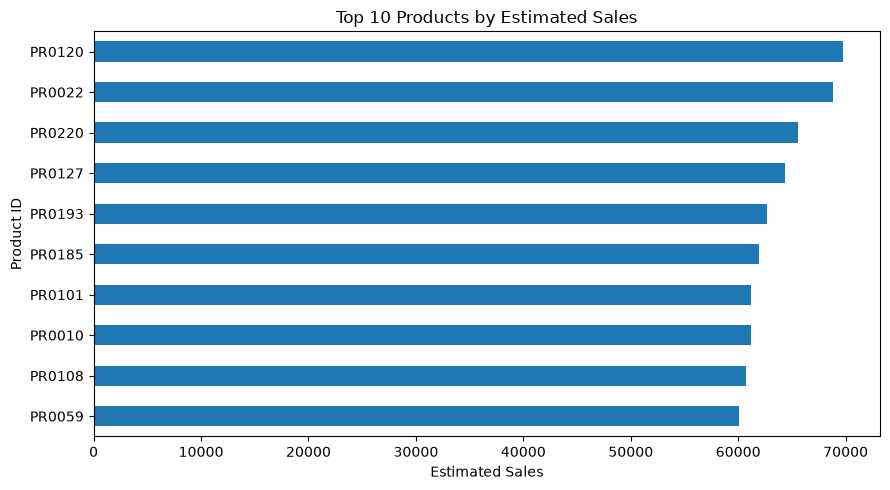


Product profitability analysis complete.


In [15]:

# ==========================================
# STEP 11: PRODUCT PROFITABILITY ANALYSIS
# ==========================================

import pandas as pd
import matplotlib.pyplot as plt

# Use completed transactions only
completed_df = df[
    df["status_clean"].eq("Completed")
].copy()

margin_col = "estimated_line_margin_before_returns"
sales_col = "estimated_discounted_line_value"

# Summarize performance by product
product_summary = (
    completed_df.groupby("product_id")
    .agg(
        category=("category", "first"),
        transaction_lines=("transaction_id", "size"),
        units_sold=("quantity", "sum"),
        estimated_sales=(sales_col, "sum"),
        estimated_margin=(margin_col, "sum"),
        average_discount=("discount_pct", "mean")
    )
)

# Calculate estimated margin percentage
product_summary["estimated_margin_pct"] = (
    product_summary["estimated_margin"]
    / product_summary["estimated_sales"].replace(0, float("nan"))
    * 100
)

product_summary = product_summary.round(2)

# Top 10 products by estimated sales
print("TOP 10 PRODUCTS BY ESTIMATED SALES")
display(
    product_summary.sort_values(
        "estimated_sales", ascending=False
    ).head(10)
)

# 10 products with the lowest estimated total margin
print("\n10 PRODUCTS WITH LOWEST ESTIMATED TOTAL MARGIN")
display(
    product_summary.sort_values(
        "estimated_margin", ascending=True
    ).head(10)
)

# Products with negative total estimated margin
negative_products = product_summary[
    product_summary["estimated_margin"] < 0
].sort_values("estimated_margin")

print("\nPRODUCTS WITH NEGATIVE TOTAL ESTIMATED MARGIN")
print("Number of products:", len(negative_products))
display(negative_products.head(15))

# Chart: Top products by estimated sales
top_products = product_summary.nlargest(10, "estimated_sales")

top_products["estimated_sales"].sort_values().plot(
    kind="barh", figsize=(9, 5)
)
plt.title("Top 10 Products by Estimated Sales")
plt.xlabel("Estimated Sales")
plt.ylabel("Product ID")
plt.tight_layout()
plt.show()

print("\nProduct profitability analysis complete.")


CATEGORY PROFITABILITY SUMMARY


,transaction_lines,units_sold,estimated_sales,estimated_margin,average_discount,estimated_margin_pct
category,,,,,,
Home,2436,7361,1390889.32,431659.48,0.08,31.03
Electronics,2535,7669,1316100.72,412263.67,0.08,31.32
Fashion,2016,6123,1076686.47,379136.86,0.08,35.21
Sports,2374,7141,1301361.92,378860.24,0.08,29.11
Grocery,2437,7273,1282925.56,300332.44,0.08,23.41
Beauty,2164,6530,933734.26,66735.71,0.08,7.15


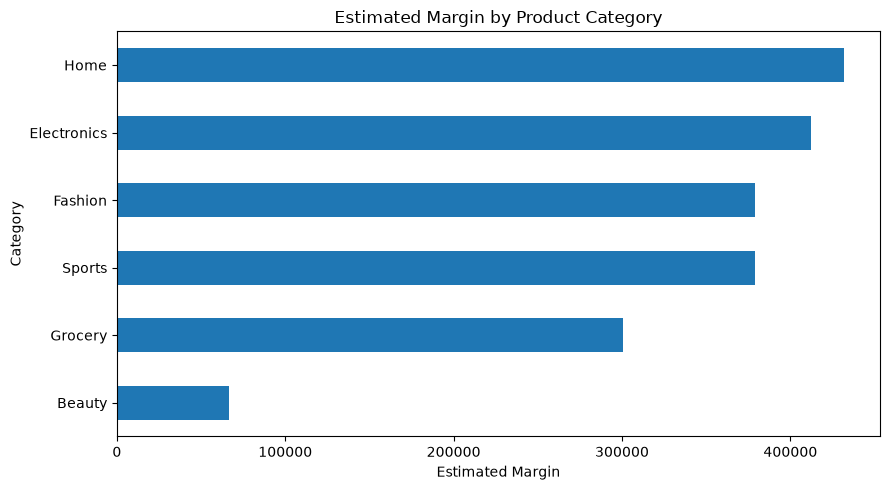

Category with the lowest estimated total margin: Beauty
Estimated margin: 66735.71


In [16]:

# STEP 12: CATEGORY PROFITABILITY ANALYSIS

import matplotlib.pyplot as plt

# Analyze completed transactions only
completed_df = df[df["status_clean"].eq("Completed")].copy()

sales_col = "estimated_discounted_line_value"
margin_col = "estimated_line_margin_before_returns"

category_summary = (
    completed_df.groupby("category")
    .agg(
        transaction_lines=("transaction_id", "size"),
        units_sold=("quantity", "sum"),
        estimated_sales=(sales_col, "sum"),
        estimated_margin=(margin_col, "sum"),
        average_discount=("discount_pct", "mean")
    )
)

category_summary["estimated_margin_pct"] = (
    category_summary["estimated_margin"]
    / category_summary["estimated_sales"].replace(0, float("nan"))
    * 100
)

category_summary = category_summary.round(2)

print("CATEGORY PROFITABILITY SUMMARY")
display(
    category_summary.sort_values(
        "estimated_margin", ascending=False
    )
)

# Plot estimated margin by category
category_summary["estimated_margin"].sort_values().plot(
    kind="barh", figsize=(9, 5)
)

plt.title("Estimated Margin by Product Category")
plt.xlabel("Estimated Margin")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

# Identify the category with the lowest estimated margin
lowest_category = category_summary["estimated_margin"].idxmin()

print("Category with the lowest estimated total margin:",
      lowest_category)
print("Estimated margin:",
      category_summary.loc[lowest_category, "estimated_margin"])


SALES CHANNEL PERFORMANCE


,transaction_lines,units_sold,estimated_sales,estimated_margin,average_discount,estimated_margin_pct
channel,,,,,,
Web,6296,19125,3320492.10,895102.99,0.08,26.96
App,5499,16429,2829459.48,742581.55,0.08,26.24
Store,2167,6543,1151746.67,331303.86,0.08,28.77


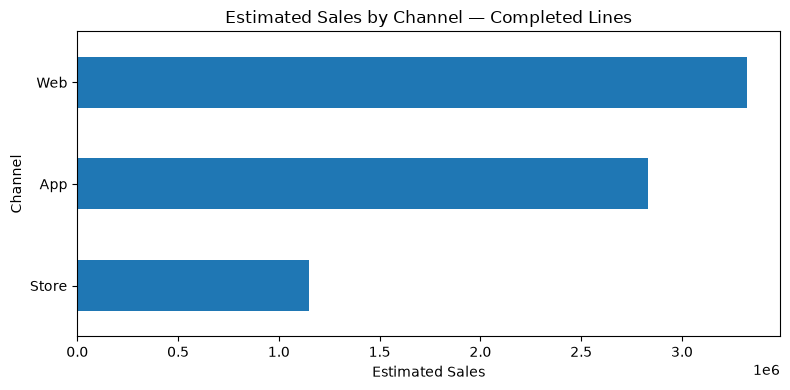

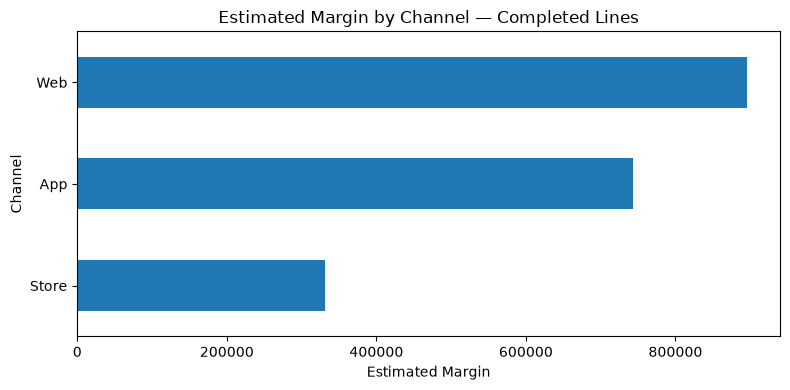

Channel analysis complete.


In [17]:

# STEP 13: SALES CHANNEL PERFORMANCE

import matplotlib.pyplot as plt

completed_df = df[df["status_clean"].eq("Completed")].copy()

sales_col = "estimated_discounted_line_value"
margin_col = "estimated_line_margin_before_returns"

channel_summary = (
    completed_df.groupby("channel")
    .agg(
        transaction_lines=("transaction_id", "size"),
        units_sold=("quantity", "sum"),
        estimated_sales=(sales_col, "sum"),
        estimated_margin=(margin_col, "sum"),
        average_discount=("discount_pct", "mean")
    )
)

channel_summary["estimated_margin_pct"] = (
    channel_summary["estimated_margin"]
    / channel_summary["estimated_sales"].replace(0, float("nan"))
    * 100
)

channel_summary = channel_summary.round(2)

print("SALES CHANNEL PERFORMANCE")
display(
    channel_summary.sort_values(
        "estimated_sales", ascending=False
    )
)

# Compare estimated sales by channel
channel_summary["estimated_sales"].sort_values().plot(
    kind="barh", figsize=(8, 4)
)

plt.title("Estimated Sales by Channel — Completed Lines")
plt.xlabel("Estimated Sales")
plt.ylabel("Channel")
plt.tight_layout()
plt.show()

# Compare estimated margin by channel
channel_summary["estimated_margin"].sort_values().plot(
    kind="barh", figsize=(8, 4)
)

plt.title("Estimated Margin by Channel — Completed Lines")
plt.xlabel("Estimated Margin")
plt.ylabel("Channel")
plt.tight_layout()
plt.show()

print("Channel analysis complete.")


DISCOUNT BAND ANALYSIS


,transaction_lines,estimated_sales,estimated_margin,average_margin
discount_band,,,,
0% (No Discount),4804,2970282.11,1154294.94,240.28
0–5%,2113,1181712.31,372244.64,176.17
5–10%,2785,1398617.96,327226.11,117.50
10–20%,3547,1509389.66,145255.91,40.95
20%+,713,241696.22,-30033.20,-42.12


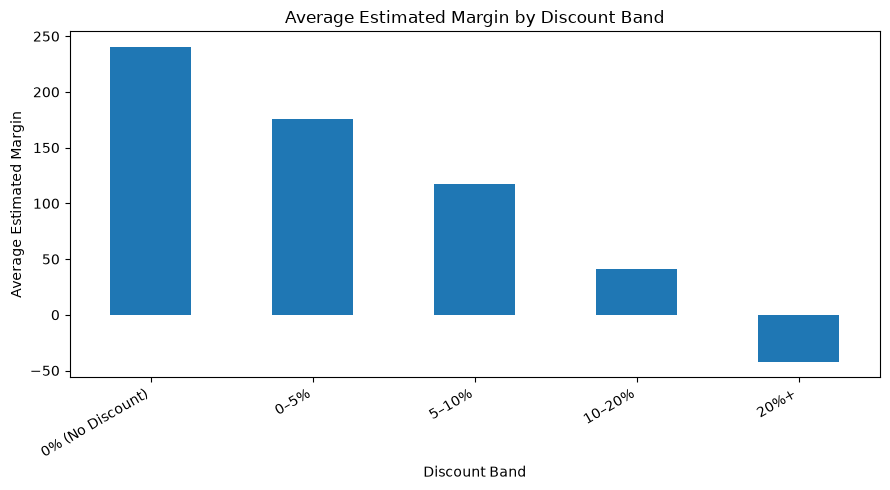

Discount impact analysis complete.


In [18]:

# STEP 14: DISCOUNT IMPACT ANALYSIS

import pandas as pd
import matplotlib.pyplot as plt

completed_df = df[df["status_clean"].eq("Completed")].copy()

sales_col = "estimated_discounted_line_value"
margin_col = "estimated_line_margin_before_returns"

# Group discount percentages into bands
completed_df["discount_band"] = pd.cut(
    completed_df["discount_pct"],
    bins=[-0.001, 0, 0.05, 0.10, 0.20, 1.0],
    labels=[
        "0% (No Discount)",
        "0–5%",
        "5–10%",
        "10–20%",
        "20%+"
    ],
    include_lowest=True
)

discount_summary = (
    completed_df.groupby("discount_band", observed=False)
    .agg(
        transaction_lines=("transaction_id", "size"),
        estimated_sales=(sales_col, "sum"),
        estimated_margin=(margin_col, "sum"),
        average_margin=(margin_col, "mean")
    )
)

discount_summary = discount_summary.round(2)

print("DISCOUNT BAND ANALYSIS")
display(discount_summary)

# Plot average estimated margin for each discount band
discount_summary["average_margin"].plot(
    kind="bar", figsize=(9, 5)
)

plt.title("Average Estimated Margin by Discount Band")
plt.xlabel("Discount Band")
plt.ylabel("Average Estimated Margin")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

print("Discount impact analysis complete.")


In [19]:

# STEP 15: RETAIL ANALYTICS KPI SUMMARY

completed_df = df[df["status_clean"].eq("Completed")].copy()

total_lines = len(completed_df)
total_sales = completed_df["estimated_discounted_line_value"].sum()
total_margin = completed_df["estimated_line_margin_before_returns"].sum()
negative_margin_lines = (
    completed_df["estimated_line_margin_before_returns"] < 0
).sum()

average_line_sales = (
    completed_df["estimated_discounted_line_value"].mean()
)

negative_margin_pct = (
    negative_margin_lines / total_lines * 100
    if total_lines else 0
)

kpi_summary = pd.DataFrame({
    "KPI": [
        "Completed Transaction Lines",
        "Estimated Sales",
        "Estimated Margin Before Returns",
        "Average Estimated Sales per Line",
        "Negative-Margin Lines",
        "Negative-Margin Lines (%)"
    ],
    "Value": [
        total_lines,
        round(total_sales, 2),
        round(total_margin, 2),
        round(average_line_sales, 2),
        negative_margin_lines,
        round(negative_margin_pct, 2)
    ]
})

display(kpi_summary)

print("KPI summary complete.")


,KPI,Value
0,Completed Transaction Lines,13962.00
1,Estimated Sales,7301698.25
2,Estimated Margin Before Returns,1968988.40
3,Average Estimated Sales per Line,522.97
4,Negative-Margin Lines,5315.00
5,Negative-Margin Lines (%),38.07


KPI summary complete.


In [20]:

# STEP 16: FINAL BUSINESS INSIGHTS AND RECOMMENDATIONS

import pandas as pd

completed_df = df[df["status_clean"].eq("Completed")].copy()

sales_col = "estimated_discounted_line_value"
margin_col = "estimated_line_margin_before_returns"

# 1. Category performance
category_summary = completed_df.groupby("category").agg(
    estimated_sales=(sales_col, "sum"),
    estimated_margin=(margin_col, "sum")
)

best_sales_category = category_summary["estimated_sales"].idxmax()
lowest_margin_category = category_summary["estimated_margin"].idxmin()

# 2. Channel performance
channel_summary = completed_df.groupby("channel").agg(
    estimated_sales=(sales_col, "sum"),
    estimated_margin=(margin_col, "sum")
)

best_sales_channel = channel_summary["estimated_sales"].idxmax()
best_margin_channel = channel_summary["estimated_margin"].idxmax()

# 3. Negative margin
negative_lines = (completed_df[margin_col] < 0).sum()
total_lines = len(completed_df)
negative_pct = negative_lines / total_lines * 100 if total_lines else 0

# 4. Summary
insights = [
    f"Highest-sales category: {best_sales_category}.",
    f"Lowest-total-margin category: {lowest_margin_category}; review product costs, pricing, and discounts.",
    f"Highest-sales channel: {best_sales_channel}.",
    f"Highest-total-margin channel: {best_margin_channel}.",
    f"{negative_lines:,} completed lines ({negative_pct:.1f}%) have negative estimated margins.",
    "Review low-margin products and validate unit costs and discount data before changing prices.",
    "Analyze returns separately and verify the meaning of each transaction status before reporting realized sales."
]

print("FINAL BUSINESS INSIGHTS")
for number, insight in enumerate(insights, start=1):
    print(f"{number}. {insight}")

# Save report for your project
with open("retail_business_insights.txt", "w", encoding="utf-8") as file:
    file.write("RETAIL ANALYTICS: BUSINESS INSIGHTS\n\n")
    for number, insight in enumerate(insights, start=1):
        file.write(f"{number}. {insight}\n")

print("\nSaved report as retail_business_insights.txt")


FINAL BUSINESS INSIGHTS
1. Highest-sales category: Home.
2. Lowest-total-margin category: Beauty; review product costs, pricing, and discounts.
3. Highest-sales channel: Web.
4. Highest-total-margin channel: Web.
5. 5,315 completed lines (38.1%) have negative estimated margins.
6. Review low-margin products and validate unit costs and discount data before changing prices.
7. Analyze returns separately and verify the meaning of each transaction status before reporting realized sales.

Saved report as retail_business_insights.txt


In [21]:

# STEP 17: EXPORT RETAIL ANALYSIS TO EXCEL

import pandas as pd

completed_df = df[df["status_clean"].eq("Completed")].copy()

sales_col = "estimated_discounted_line_value"
margin_col = "estimated_line_margin_before_returns"

# Monthly performance
completed_df["timestamp"] = pd.to_datetime(
    completed_df["timestamp"], errors="coerce"
)
completed_df["month"] = completed_df["timestamp"].dt.to_period("M").astype(str)

monthly_summary = completed_df.groupby("month").agg(
    transaction_lines=("transaction_id", "size"),
    estimated_sales=(sales_col, "sum"),
    estimated_margin=(margin_col, "sum")
).round(2)

# Category performance
category_summary = completed_df.groupby("category").agg(
    transaction_lines=("transaction_id", "size"),
    estimated_sales=(sales_col, "sum"),
    estimated_margin=(margin_col, "sum")
).round(2)

# Channel performance
channel_summary = completed_df.groupby("channel").agg(
    transaction_lines=("transaction_id", "size"),
    estimated_sales=(sales_col, "sum"),
    estimated_margin=(margin_col, "sum")
).round(2)

# Product performance
product_summary = completed_df.groupby("product_id").agg(
    category=("category", "first"),
    transaction_lines=("transaction_id", "size"),
    units_sold=("quantity", "sum"),
    estimated_sales=(sales_col, "sum"),
    estimated_margin=(margin_col, "sum")
).round(2)

# Export all tables to one Excel workbook
output_file = "retail_analytics_final_report.xlsx"

with pd.ExcelWriter(output_file, engine="openpyxl") as writer:
    monthly_summary.to_excel(writer, sheet_name="Monthly Performance")
    category_summary.to_excel(writer, sheet_name="Category Performance")
    channel_summary.to_excel(writer, sheet_name="Channel Performance")
    product_summary.to_excel(writer, sheet_name="Product Performance")

print(f"Excel report saved as: {output_file}")
print("Sheets: Monthly, Category, Channel, and Product Performance")


Excel report saved as: retail_analytics_final_report.xlsx
Sheets: Monthly, Category, Channel, and Product Performance


In [22]:

# STEP 19: INTERACTIVE RETAIL DASHBOARD
# Run this entire cell individually with Shift + Enter.

import pandas as pd
import plotly.express as px
from IPython.display import display, clear_output
import ipywidgets as widgets

# Prepare completed transactions
dash_df = df[df["status_clean"].eq("Completed")].copy()

dash_df["timestamp"] = pd.to_datetime(
    dash_df["timestamp"], errors="coerce"
)
dash_df["discount_pct"] = pd.to_numeric(
    dash_df["discount_pct"], errors="coerce"
)
dash_df["month"] = dash_df["timestamp"].dt.to_period("M").astype(str)

sales_col = "estimated_discounted_line_value"
margin_col = "estimated_line_margin_before_returns"

# Filters
categories = ["All"] + sorted(
    dash_df["category"].dropna().astype(str).unique().tolist()
)
channels = ["All"] + sorted(
    dash_df["channel"].dropna().astype(str).unique().tolist()
)

category_filter = widgets.Dropdown(
    options=categories, value="All", description="Category:"
)
channel_filter = widgets.Dropdown(
    options=channels, value="All", description="Channel:"
)

output = widgets.Output()

def render_dashboard(*args):
    with output:
        clear_output(wait=True)

        filtered = dash_df.copy()

        if category_filter.value != "All":
            filtered = filtered[
                filtered["category"].astype(str) == category_filter.value
            ]

        if channel_filter.value != "All":
            filtered = filtered[
                filtered["channel"].astype(str) == channel_filter.value
            ]

        if filtered.empty:
            print("No data available for these filters.")
            return

        total_sales = filtered[sales_col].sum()
        total_margin = filtered[margin_col].sum()
        line_count = len(filtered)
        negative_count = (filtered[margin_col] < 0).sum()
        negative_pct = (
            negative_count / line_count * 100 if line_count else 0
        )

        print("RETAIL ANALYTICS DASHBOARD")
        print("-" * 45)
        print(f"Completed lines:       {line_count:,}")
        print(f"Estimated sales:        {total_sales:,.2f}")
        print(f"Estimated margin:       {total_margin:,.2f}")
        print(f"Negative-margin lines:  {negative_count:,} ({negative_pct:.1f}%)")

        # Monthly trend
        monthly = filtered.groupby("month", as_index=False).agg(
            estimated_sales=(sales_col, "sum"),
            estimated_margin=(margin_col, "sum")
        )

        fig_month = px.line(
            monthly, x="month", y="estimated_sales",
            markers=True,
            title="Monthly Estimated Sales",
            labels={"month": "Month", "estimated_sales": "Estimated sales"}
        )
        fig_month.update_layout(template="plotly_white")
        fig_month.show()

        # Category performance
        category_data = filtered.groupby("category", as_index=False).agg(
            estimated_sales=(sales_col, "sum"),
            estimated_margin=(margin_col, "sum")
        )

        fig_category = px.bar(
            category_data.sort_values("estimated_margin"),
            x="estimated_margin", y="category",
            orientation="h", color="estimated_margin",
            title="Estimated Margin by Category",
            labels={
                "estimated_margin": "Estimated margin",
                "category": "Category"
            },
            color_continuous_scale="Teal"
        )
        fig_category.update_layout(template="plotly_white")
        fig_category.show()

        # Channel performance
        channel_data = filtered.groupby("channel", as_index=False).agg(
            estimated_sales=(sales_col, "sum"),
            estimated_margin=(margin_col, "sum")
        )

        fig_channel = px.bar(
            channel_data, x="channel",
            y=["estimated_sales", "estimated_margin"],
            barmode="group",
            title="Sales and Margin by Channel",
            labels={
                "channel": "Channel",
                "value": "Estimated amount",
                "variable": "Metric"
            }
        )
        fig_channel.update_layout(template="plotly_white")
        fig_channel.show()

        # Product table
        products = filtered.groupby("product_id", as_index=False).agg(
            transaction_lines=("transaction_id", "size"),
            units_sold=("quantity", "sum"),
            estimated_sales=(sales_col, "sum"),
            estimated_margin=(margin_col, "sum")
        )

        print("TOP 10 PRODUCTS BY ESTIMATED SALES")
        display(
            products.sort_values("estimated_sales", ascending=False)
            .head(10).round(2)
        )

category_filter.observe(render_dashboard, names="value")
channel_filter.observe(render_dashboard, names="value")

display(widgets.HBox([category_filter, channel_filter]))
display(output)
render_dashboard()


Output()

In [25]:

import os
import pandas as pd
from IPython.display import display

# Correct folder path
ml_output_dir = r"C:\Users\adria\ml_model_outputs"

evaluation_path = os.path.join(
    ml_output_dir, "model_evaluation.csv"
)
predictions_path = os.path.join(
    ml_output_dir, "demand_predictions.csv"
)

# Verify files before loading
assert os.path.exists(evaluation_path), "Evaluation file not found!"
assert os.path.exists(predictions_path), "Predictions file not found!"

evaluation_df = pd.read_csv(evaluation_path)
predictions_df = pd.read_csv(predictions_path)

print("ML model results loaded successfully!")

print("\nMODEL PERFORMANCE")
display(evaluation_df.round(3))

print("\nSAMPLE PRODUCT DEMAND PREDICTIONS")
display(predictions_df.head(10))


ML model results loaded successfully!

MODEL PERFORMANCE


,model,MAE,RMSE
0,Random Forest,0.85,1.288
1,7-day baseline,0.77,1.364



SAMPLE PRODUCT DEMAND PREDICTIONS


,date,product_id,category,actual_units_sold,predicted_units_sold,baseline_predicted_units,absolute_error
0,2025-10-20,PR0001,Sports,0.0,0.518440,0.000000,0.518440
1,2025-10-21,PR0001,Sports,0.0,0.505106,0.000000,0.505106
2,2025-10-22,PR0001,Sports,0.0,0.504710,0.000000,0.504710
3,2025-10-23,PR0001,Sports,0.0,0.507438,0.000000,0.507438
4,2025-10-24,PR0001,Sports,1.0,0.523386,0.000000,0.476614
5,2025-10-25,PR0001,Sports,1.0,0.550150,0.142857,0.449850
6,2025-10-26,PR0001,Sports,0.0,0.505329,0.285714,0.505329
7,2025-10-27,PR0001,Sports,0.0,0.476775,0.285714,0.476775
8,2025-10-28,PR0001,Sports,0.0,0.464284,0.285714,0.464284
9,2025-10-29,PR0001,Sports,0.0,0.464284,0.285714,0.464284


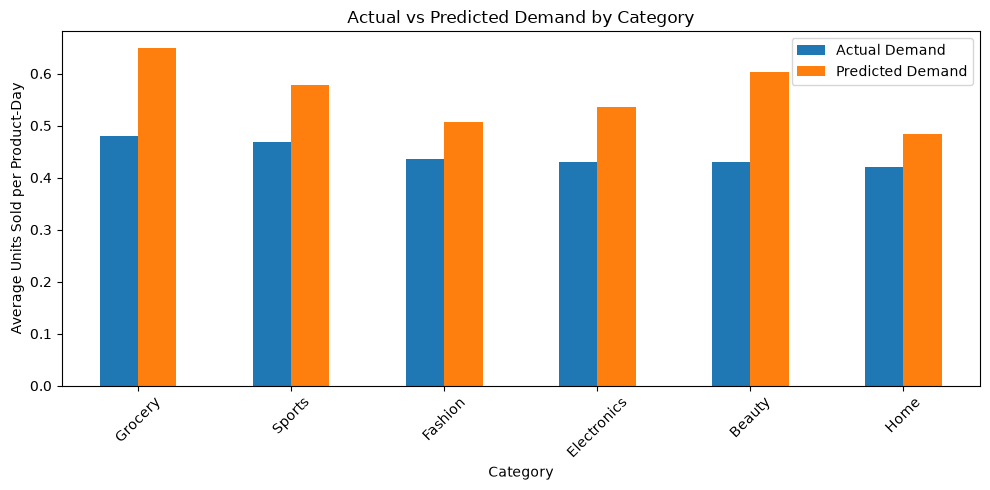

In [26]:

import matplotlib.pyplot as plt

category_prediction_summary = (
    predictions_df
    .groupby("category", as_index=False)
    .agg(
        actual_units=("actual_units_sold", "mean"),
        predicted_units=("predicted_units_sold", "mean")
    )
    .sort_values("actual_units", ascending=False)
)

category_prediction_summary.plot(
    x="category",
    y=["actual_units", "predicted_units"],
    kind="bar",
    figsize=(10, 5)
)

plt.title("Actual vs Predicted Demand by Category")
plt.xlabel("Category")
plt.ylabel("Average Units Sold per Product-Day")
plt.xticks(rotation=45)
plt.legend(["Actual Demand", "Predicted Demand"])
plt.tight_layout()
plt.show()


# Machine Learning: Product Demand Prediction

Random Forest Regression compared with a 7-day moving-average baseline.

## Model Performance

,model,MAE,RMSE
0,Random Forest,0.85,1.288
1,7-day baseline,0.77,1.364


Random Forest MAE: 0.850 units
Baseline MAE:      0.770 units
Random Forest RMSE: 1.288 units
Baseline RMSE:      1.364 units


## Model vs Baseline

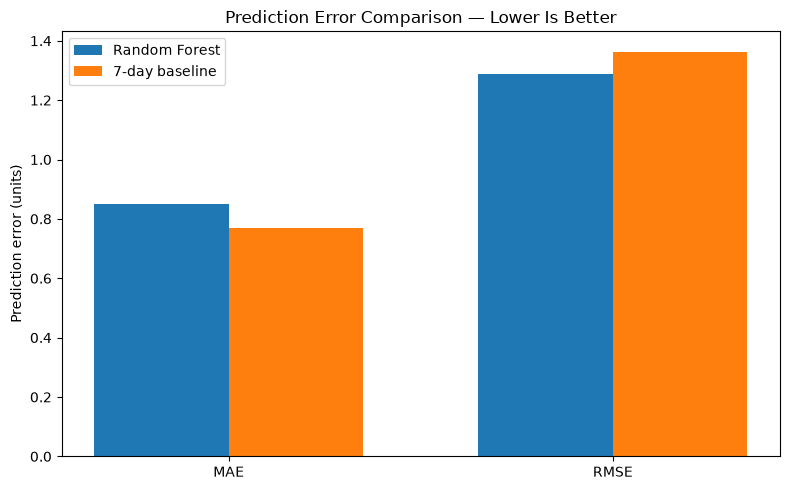

## Actual vs Predicted Demand

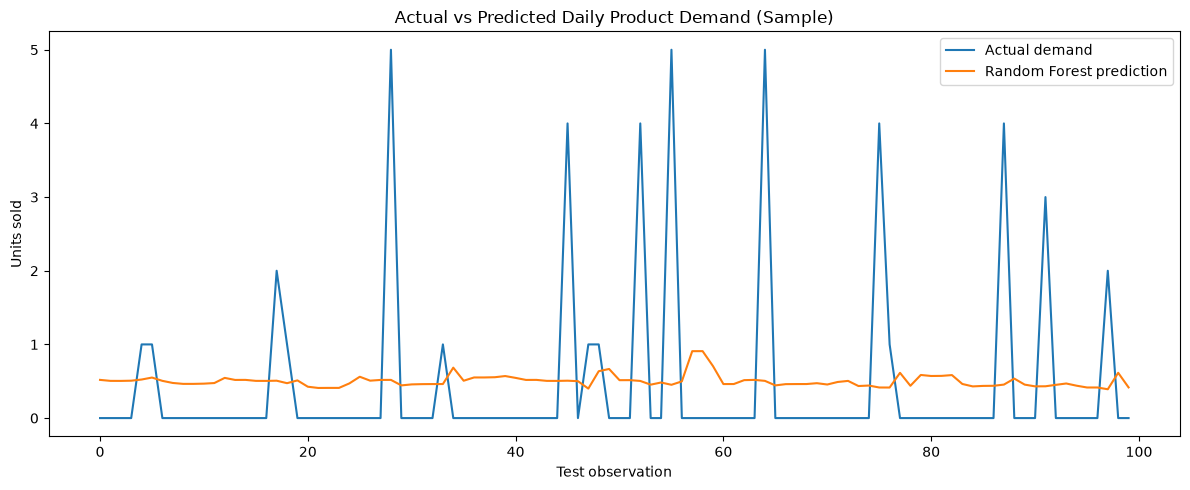

## Demand Prediction by Category

,category,actual_units,predicted_units
3,Grocery,0.480,0.649
5,Sports,0.468,0.578
2,Fashion,0.436,0.506
1,Electronics,0.431,0.536
0,Beauty,0.430,0.604
4,Home,0.421,0.484


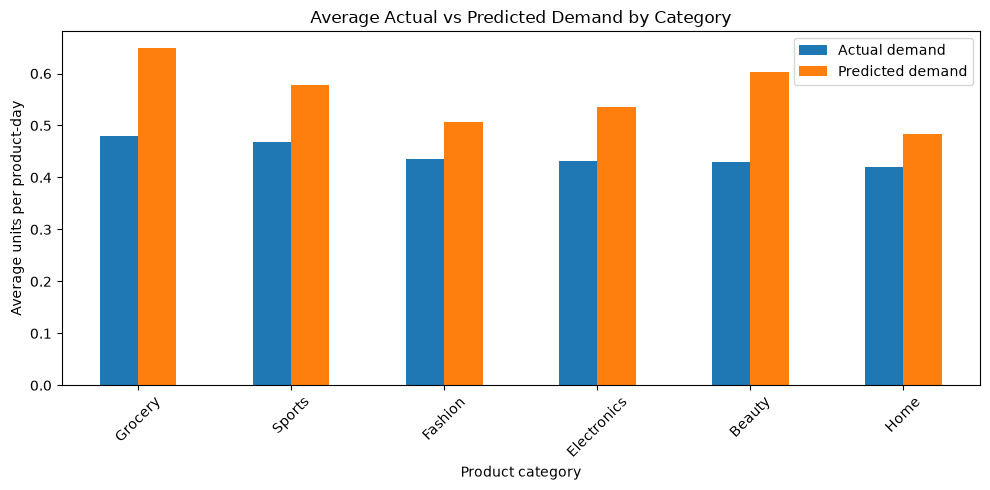

## ML Findings

Results are mixed: Random Forest performed better on one metric, while the baseline performed better on the other.
These are test-period predictions, not forecasts for dates beyond the available dataset.


In [27]:

# ==========================================
# RETAIL ANALYTICS DASHBOARD - ML SECTION
# ==========================================

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# 1. Load saved ML outputs
ml_output_dir = r"C:\Users\adria\ml_model_outputs"

evaluation_df = pd.read_csv(
    os.path.join(ml_output_dir, "model_evaluation.csv")
)

predictions_df = pd.read_csv(
    os.path.join(ml_output_dir, "demand_predictions.csv")
)

# 2. Display section heading
display(Markdown("# Machine Learning: Product Demand Prediction"))
display(Markdown(
    "Random Forest Regression compared with a 7-day moving-average baseline."
))

# 3. Show model metrics
display(Markdown("## Model Performance"))

display(evaluation_df.round(3))

# Retrieve metrics by model name
metrics = evaluation_df.set_index("model")

rf_mae = metrics.loc["Random Forest", "MAE"]
rf_rmse = metrics.loc["Random Forest", "RMSE"]

baseline_mae = metrics.loc["7-day baseline", "MAE"]
baseline_rmse = metrics.loc["7-day baseline", "RMSE"]

print(f"Random Forest MAE: {rf_mae:.3f} units")
print(f"Baseline MAE:      {baseline_mae:.3f} units")
print(f"Random Forest RMSE: {rf_rmse:.3f} units")
print(f"Baseline RMSE:      {baseline_rmse:.3f} units")

# 4. Compare MAE and RMSE
display(Markdown("## Model vs Baseline"))

metric_names = ["MAE", "RMSE"]
rf_values = [rf_mae, rf_rmse]
baseline_values = [baseline_mae, baseline_rmse]

x = np.arange(len(metric_names))
width = 0.35

fig, ax = plt.subplots(figsize=(8, 5))

ax.bar(x - width / 2, rf_values, width, label="Random Forest")
ax.bar(x + width / 2, baseline_values, width, label="7-day baseline")

ax.set_xticks(x)
ax.set_xticklabels(metric_names)
ax.set_ylabel("Prediction error (units)")
ax.set_title("Prediction Error Comparison — Lower Is Better")
ax.legend()

plt.tight_layout()
plt.show()

# 5. Actual vs predicted demand for a sample
display(Markdown("## Actual vs Predicted Demand"))

sample_results = predictions_df.head(100).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    sample_results.index,
    sample_results["actual_units_sold"],
    label="Actual demand"
)

ax.plot(
    sample_results.index,
    sample_results["predicted_units_sold"],
    label="Random Forest prediction"
)

ax.set_xlabel("Test observation")
ax.set_ylabel("Units sold")
ax.set_title("Actual vs Predicted Daily Product Demand (Sample)")
ax.legend()

plt.tight_layout()
plt.show()

# 6. Category-level comparison
display(Markdown("## Demand Prediction by Category"))

category_summary = (
    predictions_df
    .groupby("category", as_index=False)
    .agg(
        actual_units=("actual_units_sold", "mean"),
        predicted_units=("predicted_units_sold", "mean")
    )
    .sort_values("actual_units", ascending=False)
)

display(category_summary.round(3))

category_summary.plot(
    x="category",
    y=["actual_units", "predicted_units"],
    kind="bar",
    figsize=(10, 5)
)

plt.title("Average Actual vs Predicted Demand by Category")
plt.xlabel("Product category")
plt.ylabel("Average units per product-day")
plt.xticks(rotation=45)
plt.legend(["Actual demand", "Predicted demand"])
plt.tight_layout()
plt.show()

# 7. Automatically generate a conclusion
display(Markdown("## ML Findings"))

if rf_mae < baseline_mae and rf_rmse < baseline_rmse:
    conclusion = (
        "Random Forest outperformed the baseline on both error metrics."
    )
elif rf_mae > baseline_mae and rf_rmse > baseline_rmse:
    conclusion = (
        "The 7-day baseline outperformed Random Forest on both error metrics."
    )
else:
    conclusion = (
        "Results are mixed: Random Forest performed better on one metric, "
        "while the baseline performed better on the other."
    )

print(conclusion)
print(
    "These are test-period predictions, not forecasts for dates beyond "
    "the available dataset."
)


In [34]:
# ================================================================
# RETAIL ANALYTICS EXECUTIVE DASHBOARD
# Standalone, colourful HTML dashboard for Jupyter Notebook.
# Run this complete file as one cell, or execute it as a Python script.
# Plotly.js is embedded once in the HTML so charts render consistently
# from a local file and do not depend on a CDN or internet connection.
# ================================================================

from pathlib import Path
from IPython.display import display, HTML
import html as html_lib
import webbrowser
import warnings
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from plotly.offline import get_plotlyjs

warnings.filterwarnings("ignore", category=FutureWarning)

# --------------------------- PATHS -------------------------------

HOME = Path.home()
DATA_CANDIDATES = [
    HOME / "Downloads" / "cleaned_output" / "retail_master_transactions.csv",
    Path.cwd() / "cleaned_output" / "retail_master_transactions.csv",
    Path.cwd() / "retail_master_transactions.csv",
]
MASTER_FILE = next((p for p in DATA_CANDIDATES if p.exists()), None)

if MASTER_FILE is None:
    searched = "\n".join(str(p) for p in DATA_CANDIDATES)
    raise FileNotFoundError(
        "Could not find retail_master_transactions.csv. Checked:\n" + searched
    )

ML_DIR_CANDIDATES = [
    HOME / "ml_model_outputs",
    Path.cwd() / "ml_model_outputs",
    Path(r"C:\Users\adria\ml_model_outputs"),
    HOME / "Downloads" / "ml_model_outputs",
]
ML_DIR = next(
    (p for p in ML_DIR_CANDIDATES if (p / "demand_predictions.csv").exists()),
    next((p for p in ML_DIR_CANDIDATES if p.exists()), ML_DIR_CANDIDATES[0])
)
OUT_FILE = Path.cwd() / "retail_dashboard.html"

# ------------------------- HELPERS -------------------------------

PALETTE = [
    "#6C63FF", "#FF6584", "#36D6C5", "#FFB84D", "#4DA8FF",
    "#B57BFF", "#2ECC71", "#FF8A5B", "#22C7D9", "#F472B6"
]


def find_col(frame, candidates):
    """Find a column by case-insensitive exact name."""
    if frame is None or frame.empty:
        return None
    lookup = {str(c).strip().lower(): c for c in frame.columns}
    for candidate in candidates:
        if candidate.lower() in lookup:
            return lookup[candidate.lower()]
    return None


def esc(value):
    return html_lib.escape(str(value), quote=True)


def money(value):
    try:
        value = float(value)
    except (TypeError, ValueError):
        return "N/A"
    if not np.isfinite(value):
        return "N/A"
    if abs(value) >= 1_000_000:
        return f"{value / 1_000_000:,.2f}M"
    if abs(value) >= 1_000:
        return f"{value / 1_000:,.1f}K"
    return f"{value:,.0f}"


def fmt_num(value, decimals=1):
    try:
        value = float(value)
    except (TypeError, ValueError):
        return "N/A"
    if not np.isfinite(value):
        return "N/A"
    return f"{value:,.{decimals}f}"


def truthy(series):
    """Safely treat common bool, number, and text values as True/False."""
    if series is None:
        return pd.Series(dtype=bool)
    return (
        series.astype("string").str.strip().str.lower()
        .isin(["1", "true", "yes", "y", "t"])
    )


def read_csv_if_exists(path, **kwargs):
    path = Path(path)
    if not path.exists():
        return pd.DataFrame()
    try:
        return pd.read_csv(path, low_memory=False, **kwargs)
    except Exception as exc:
        print(f"Warning: Could not read {path.name}: {exc}")
        return pd.DataFrame()


def prepare_figure(fig, height=390):
    """Consistent styling; chart containers remain responsive."""
    fig.update_layout(
        template="plotly_white",
        colorway=PALETTE,
        height=height,
        autosize=True,
        margin=dict(l=18, r=18, t=64, b=48),
        title=dict(font=dict(size=16, color="#26234A"), x=0.02, xanchor="left"),
        font=dict(family="Inter, Segoe UI, Arial, sans-serif", color="#373653", size=12),
        paper_bgcolor="rgba(255,255,255,0)",
        plot_bgcolor="rgba(255,255,255,0)",
        legend=dict(orientation="h", yanchor="top", y=-0.20, x=0),
    )
    fig.update_xaxes(showgrid=False, automargin=True, zeroline=False)
    fig.update_yaxes(gridcolor="#ECECF5", automargin=True, zeroline=False)
    return fig


charts = {}


def put(key, fig):
    """Store a chart fragment. Plotly.js is loaded exactly once in <head>."""
    prepare_figure(fig)
    charts[key] = fig.to_html(
        full_html=False,
        include_plotlyjs=False,
        config={"displaylogo": False, "responsive": True, "scrollZoom": False},
        default_width="100%",
        default_height="390px",
    )


def unavailable(message):
    return f'<div class="empty-chart">{esc(message)}</div>'


def chart_card(key, title, explanation):
    chart = charts.get(key, unavailable("Not enough data to draw this chart."))
    return (
        '<article class="chart-card">'
        f'<div class="chart-intro"><h3>{esc(title)}</h3><p>{esc(explanation)}</p></div>'
        f'<div class="chart-area">{chart}</div>'
        '</article>'
    )


def group_sum(frame, group_col, value_col, label):
    if frame.empty or group_col is None or value_col is None:
        return pd.DataFrame(columns=[label, "Value"])
    data = frame[[group_col, value_col]].copy()
    data[group_col] = data[group_col].astype("string").fillna("Unknown")
    data[value_col] = pd.to_numeric(data[value_col], errors="coerce")
    return (
        data.groupby(group_col, dropna=False)[value_col]
        .sum(min_count=1).reset_index()
        .rename(columns={group_col: label, value_col: "Value"})
    )


def add_bar(key, data, x, y, title, horizontal=False, color=None, color_scale=None):
    if data is None or data.empty or x not in data.columns or y not in data.columns:
        return
    try:
        if horizontal:
            fig = px.bar(
                data, x=x, y=y, orientation="h", title=title,
                color=color, color_continuous_scale=color_scale
            )
        else:
            fig = px.bar(
                data, x=x, y=y, title=title,
                color=color, color_continuous_scale=color_scale
            )
        put(key, fig)
    except Exception as exc:
        charts[key] = unavailable(f"Could not create chart: {exc}")


def add_pie(key, data, names, values, title):
    if data is None or data.empty or names not in data.columns or values not in data.columns:
        return
    try:
        fig = px.pie(
            data, names=names, values=values, title=title,
            hole=0.48, color_discrete_sequence=PALETTE
        )
        fig.update_traces(textposition="inside", textinfo="percent+label", insidetextorientation="auto")
        put(key, fig)
    except Exception as exc:
        charts[key] = unavailable(f"Could not create chart: {exc}")


def safe_metric_sum(frame, col):
    if col is None or col not in frame.columns:
        return np.nan
    values = pd.to_numeric(frame[col], errors="coerce")
    return values.sum(min_count=1)


def kpi_card(label, value, detail, color):
    return (
        f'<article class="kpi {esc(color)}">'
        f'<div class="kpi-label">{esc(label)}</div>'
        f'<div class="kpi-value">{esc(value)}</div>'
        f'<div class="kpi-detail">{esc(detail)}</div>'
        '</article>'
    )

# ---------------------- LOAD TRANSACTIONS ------------------------

df = pd.read_csv(MASTER_FILE, low_memory=False)
if df.empty:
    raise ValueError(f"The transaction file is empty: {MASTER_FILE}")

DATE_COL = find_col(df, ["timestamp", "transaction_date", "order_date", "date"])
STATUS_COL = find_col(df, ["status", "transaction_status", "order_status"])
SALES_COL = find_col(df, [
    "estimated_discounted_line_value", "net_sales", "sales_value",
    "revenue", "line_total", "total_amount"
])
MARGIN_COL = find_col(df, [
    "estimated_line_margin_before_returns", "line_margin", "profit", "margin_value"
])
QTY_COL = find_col(df, ["quantity", "qty", "units", "units_sold"])
CATEGORY_COL = find_col(df, ["category", "product_category"])
CHANNEL_COL = find_col(df, ["channel", "sales_channel"])
PAYMENT_COL = find_col(df, ["payment_method", "payment_type"])
REGION_COL = find_col(df, ["region", "sales_region"])
SEGMENT_COL = find_col(df, ["customer_segment", "segment"])
PRODUCT_COL = find_col(df, ["product_id", "sku", "product"])
CUSTOMER_COL = find_col(df, ["customer_id", "client_id"])
DISCOUNT_COL = find_col(df, ["discount_pct", "discount_percent", "discount"])

if DATE_COL:
    df[DATE_COL] = pd.to_datetime(df[DATE_COL], errors="coerce")

for col in [SALES_COL, MARGIN_COL, QTY_COL, DISCOUNT_COL]:
    if col:
        df[col] = pd.to_numeric(df[col], errors="coerce")

if STATUS_COL:
    df["_status_clean"] = df[STATUS_COL].astype("string").str.strip().str.title().fillna("Unknown")
    done = df[df["_status_clean"].str.lower().eq("completed")].copy()
    if done.empty:
        done = df.copy()
        status_note = "No rows were labelled Completed, so KPIs use all available rows."
    else:
        status_note = "Headline KPIs use Completed transaction rows."
else:
    df["_status_clean"] = "All transactions"
    done = df.copy()
    status_note = "No transaction-status column found; KPIs use all available rows."

if SALES_COL is None:
    unit_price_col = find_col(df, ["unit_price", "selling_price", "price"])
    if QTY_COL and unit_price_col:
        df[unit_price_col] = pd.to_numeric(df[unit_price_col], errors="coerce")
        df["_dashboard_sales"] = df[QTY_COL] * df[unit_price_col]
        SALES_COL = "_dashboard_sales"
    else:
        raise ValueError(
            "Could not find a usable sales column or quantity/price pair. "
            f"Columns found: {', '.join(map(str, df.columns))}"
        )

# Re-copy to include a derived sales column if one was created.
if "_dashboard_sales" in df.columns:
    done = df.loc[done.index].copy()
    # make sure any derived sales values are present
    if SALES_COL == "_dashboard_sales":
        done[SALES_COL] = pd.to_numeric(done[SALES_COL], errors="coerce")

sales_total = safe_metric_sum(done, SALES_COL)
margin_total = safe_metric_sum(done, MARGIN_COL)
line_count = len(done)
valid_margin = pd.to_numeric(done[MARGIN_COL], errors="coerce") if MARGIN_COL else pd.Series(dtype=float)
negative_pct = (
    valid_margin.lt(0).sum() / valid_margin.notna().sum() * 100
    if not valid_margin.empty and valid_margin.notna().any() else np.nan
)
margin_pct = (
    margin_total / sales_total * 100
    if pd.notna(margin_total) and pd.notna(sales_total) and sales_total != 0
    else np.nan
)
avg_line_sales = (
    pd.to_numeric(done[SALES_COL], errors="coerce").mean()
    if line_count else np.nan
)
unique_customers = done[CUSTOMER_COL].nunique() if CUSTOMER_COL else np.nan
unique_products = done[PRODUCT_COL].nunique() if PRODUCT_COL else np.nan

# -------------------------- SALES TREND --------------------------

if DATE_COL and done[DATE_COL].notna().any():
    date_data = done.dropna(subset=[DATE_COL]).copy()
    date_data["_month"] = date_data[DATE_COL].dt.to_period("M").astype(str)
    monthly = date_data.groupby("_month", as_index=False).agg(
        sales=(SALES_COL, "sum"),
        **({"margin": (MARGIN_COL, "sum")} if MARGIN_COL else {})
    )

    fig = make_subplots(specs=[[{"secondary_y": True}]])
    fig.add_trace(go.Bar(
        x=monthly["_month"], y=monthly["sales"], name="Sales",
        marker_color="#6C63FF", opacity=0.88
    ), secondary_y=False)
    if MARGIN_COL:
        fig.add_trace(go.Scatter(
            x=monthly["_month"], y=monthly["margin"], name="Margin",
            mode="lines+markers", line=dict(color="#FF6584", width=3),
            marker=dict(size=7)
        ), secondary_y=True)
    fig.update_layout(title="Monthly Sales and Estimated Margin", barmode="group")
    fig.update_yaxes(title_text="Sales", secondary_y=False, gridcolor="#ECECF5")
    if MARGIN_COL:
        fig.update_yaxes(title_text="Margin", secondary_y=True, showgrid=False)
    put("monthly", fig)
else:
    monthly = pd.DataFrame(columns=["_month", "sales"])
    charts["monthly"] = unavailable("No valid transaction dates are available for the monthly trend.")

# ----------------------- CATEGORY / CHANNEL ----------------------

if CATEGORY_COL:
    category_sales = group_sum(done, CATEGORY_COL, SALES_COL, "Category")
    category_sales = category_sales.sort_values("Value", ascending=True).tail(12)
    add_bar("cat_sales", category_sales, "Value", "Category", "Sales by Category", horizontal=True)

    if MARGIN_COL:
        cat_both = done.groupby(CATEGORY_COL, dropna=False).agg(
            sales=(SALES_COL, "sum"), margin=(MARGIN_COL, "sum")
        ).reset_index()
        cat_both["margin_pct"] = np.where(
            cat_both["sales"].ne(0), cat_both["margin"] / cat_both["sales"] * 100, np.nan
        )
        cat_both = cat_both.dropna(subset=["margin_pct"]).sort_values("margin_pct")
        cat_both = cat_both.tail(12) if len(cat_both) > 12 else cat_both
        add_bar("cat_margin", cat_both, "margin_pct", CATEGORY_COL,
                "Estimated Margin Rate by Category", horizontal=True, color="margin_pct",
                color_scale="RdYlGn")
    else:
        cat_both = pd.DataFrame()
else:
    category_sales = pd.DataFrame()
    cat_both = pd.DataFrame()

if CHANNEL_COL:
    channel_sales = group_sum(done, CHANNEL_COL, SALES_COL, "Channel")
    add_pie("channel", channel_sales, "Channel", "Value", "Share of Sales by Channel")
if PAYMENT_COL:
    payment_sales = group_sum(done, PAYMENT_COL, SALES_COL, "Payment Method")
    add_pie("payment", payment_sales, "Payment Method", "Value", "Sales by Payment Method")
if REGION_COL:
    region_sales = group_sum(done, REGION_COL, SALES_COL, "Region").sort_values("Value")
    add_bar("region", region_sales, "Value", "Region", "Sales by Region", horizontal=True)
if SEGMENT_COL:
    segment_sales = group_sum(done, SEGMENT_COL, SALES_COL, "Customer Segment")
    add_pie("segment", segment_sales, "Customer Segment", "Value", "Sales by Customer Segment")

# ---------------------- DISCOUNTS / PRODUCTS ---------------------

if DISCOUNT_COL and MARGIN_COL:
    discount = pd.to_numeric(done[DISCOUNT_COL], errors="coerce")
    # Infer whether discount was stored as 0.10 or 10.0; do not alter original data.
    if discount.notna().any() and discount.max() > 1.0:
        discount = discount / 100.0
    discount = discount.clip(lower=0, upper=1)
    bins = [-0.000001, 0, 0.05, 0.10, 0.20, 1.000001]
    labels = ["0%", ">0–5%", ">5–10%", ">10–20%", ">20%"]
    discount_frame = pd.DataFrame({
        "Discount band": pd.cut(discount, bins=bins, labels=labels, include_lowest=True),
        "Margin": pd.to_numeric(done[MARGIN_COL], errors="coerce")
    })
    discount_summary = discount_frame.groupby("Discount band", observed=False)["Margin"].mean().reset_index()
    discount_summary = discount_summary.dropna(subset=["Margin"])
    add_bar("discount", discount_summary, "Discount band", "Margin",
            "Average Margin per Line by Discount Band", color="Margin", color_scale="RdYlGn")

if PRODUCT_COL:
    product_fields = {"sales": (SALES_COL, "sum")}
    if MARGIN_COL:
        product_fields["margin"] = (MARGIN_COL, "sum")
    product_rollup = done.groupby(PRODUCT_COL, dropna=False).agg(**product_fields).reset_index()

    if CATEGORY_COL:
        product_cat = done.groupby(PRODUCT_COL, dropna=False)[CATEGORY_COL].first().reset_index()
        product_rollup = product_rollup.merge(product_cat, on=PRODUCT_COL, how="left")
    else:
        product_rollup["category_label"] = "Product"
        CATEGORY_COL_FOR_PRODUCT = "category_label"

    if not product_rollup.empty:
        top_products = product_rollup.nlargest(10, "sales").sort_values("sales", ascending=True)
        color_by = CATEGORY_COL if CATEGORY_COL else None
        add_bar("top_prod", top_products, "sales", PRODUCT_COL, "Top 10 Products by Sales",
                horizontal=True, color=color_by)

        if MARGIN_COL:
            low_products = product_rollup.nsmallest(10, "margin").sort_values("margin", ascending=True)
            add_bar("low_prod", low_products, "margin", PRODUCT_COL,
                    "Products with Lowest Estimated Margin", horizontal=True,
                    color="margin", color_scale="RdYlGn")

# -------------------------- STATUS MIX --------------------------

status_counts = df["_status_clean"].value_counts(dropna=False).rename_axis("Status").reset_index(name="Lines")
add_pie("status", status_counts, "Status", "Lines", "Transaction Status Mix")

# -------------------------- INVENTORY ----------------------------

stockout_col = find_col(df, ["stockout_flag", "stockout"])
below_reorder_col = find_col(df, ["inventory_below_reorder_threshold", "below_reorder_threshold"])
stale_col = find_col(df, ["inventory_snapshot_stale_over_30_days", "snapshot_stale_over_30_days"])
inventory_date_col = find_col(df, ["inventory_date", "inventory_snapshot_date", "snapshot_date"])

inventory_rows = []
if stockout_col:
    inventory_rows.append({"Signal": "Stockout flagged", "Records": int(truthy(df[stockout_col]).sum())})
if below_reorder_col:
    inventory_rows.append({"Signal": "Below reorder threshold", "Records": int(truthy(df[below_reorder_col]).sum())})
if stale_col:
    inventory_rows.append({"Signal": "Snapshot older than 30 days", "Records": int(truthy(df[stale_col]).sum())})
if inventory_date_col:
    inventory_rows.append({"Signal": "Missing inventory snapshot", "Records": int(df[inventory_date_col].isna().sum())})

if inventory_rows:
    inventory_summary = pd.DataFrame(inventory_rows)
    add_bar("inventory", inventory_summary, "Records", "Signal",
            "Inventory Risk Signals", horizontal=True)

# -------------------------- ML OUTPUTS --------------------------

pred_file = ML_DIR / "demand_predictions.csv"
eval_file = ML_DIR / "model_evaluation.csv"
importance_file = ML_DIR / "feature_importance.csv"
pr = read_csv_if_exists(pred_file)
ev = read_csv_if_exists(eval_file)
fi = read_csv_if_exists(importance_file)

ml_cards_html = ""
ml_note = "No prediction file was found. This dashboard does not train a model by itself. Run ml_model.ipynb first to generate model outputs."
ml_status = "No prediction output found"

if not pr.empty:
    pred_date_col = find_col(pr, ["date", "timestamp", "forecast_date", "prediction_date", "ds"])
    actual_col = find_col(pr, ["actual_units_sold", "actual", "actual_demand", "actual_quantity", "actual_sales", "y_true"])
    rf_col = find_col(pr, ["predicted_units_sold", "predicted", "prediction", "predicted_demand", "predicted_quantity", "y_pred", "random_forest_prediction"])
    baseline_col = find_col(pr, ["baseline_predicted_units", "baseline_prediction", "baseline", "predicted_baseline_units"])
    ml_category_col = find_col(pr, ["category", "product_category"])
    ml_product_col = find_col(pr, ["product_id", "sku", "product"])

    if pred_date_col:
        pr[pred_date_col] = pd.to_datetime(pr[pred_date_col], errors="coerce")

    if actual_col and rf_col:
        pr[actual_col] = pd.to_numeric(pr[actual_col], errors="coerce")
        pr[rf_col] = pd.to_numeric(pr[rf_col], errors="coerce")
        if baseline_col:
            pr[baseline_col] = pd.to_numeric(pr[baseline_col], errors="coerce")

        valid = pr.dropna(subset=[actual_col, rf_col]).copy()
        if not valid.empty:
            actual_total = valid[actual_col].sum()
            predicted_total = valid[rf_col].sum()
            bias_pct = ((predicted_total - actual_total) / actual_total * 100) if actual_total else np.nan
            mae = float(np.mean(np.abs(valid[actual_col] - valid[rf_col])))
            rmse = float(np.sqrt(np.mean((valid[actual_col] - valid[rf_col]) ** 2)))
            detail_period = ""
            if pred_date_col and valid[pred_date_col].notna().any():
                dt_min = valid[pred_date_col].min().strftime("%d %b %Y")
                dt_max = valid[pred_date_col].max().strftime("%d %b %Y")
                detail_period = f"Prediction test period: {dt_min} – {dt_max}. "

            ml_cards_html += kpi_card("Actual units", fmt_num(actual_total, 0), "Observed units in prediction rows", "green")
            ml_cards_html += kpi_card("Predicted units", fmt_num(predicted_total, 0), "Model output on the same rows", "purple")
            ml_cards_html += kpi_card("Random Forest MAE", fmt_num(mae, 3), "Average absolute error per row", "blue")
            ml_cards_html += kpi_card("Random Forest RMSE", fmt_num(rmse, 3), "Penalises larger errors", "pink")
            ml_cards_html += kpi_card("Prediction bias", f"{bias_pct:+.1f}%" if pd.notna(bias_pct) else "N/A", "Positive means total predictions exceed actuals", "orange")

            # Actual vs predicted aggregate by test date.
            if pred_date_col and valid[pred_date_col].notna().any():
                agg_fields = {"actual": (actual_col, "sum"), "random_forest": (rf_col, "sum")}
                if baseline_col:
                    agg_fields["baseline"] = (baseline_col, "sum")
                daily = valid.dropna(subset=[pred_date_col]).groupby(pred_date_col, as_index=False).agg(**agg_fields)
                if not daily.empty:
                    fig = go.Figure()
                    fig.add_trace(go.Scatter(x=daily[pred_date_col], y=daily["actual"], name="Actual", mode="lines+markers", line=dict(color="#2ECC71", width=3)))
                    fig.add_trace(go.Scatter(x=daily[pred_date_col], y=daily["random_forest"], name="Random Forest", mode="lines+markers", line=dict(color="#6C63FF", width=3)))
                    if baseline_col:
                        fig.add_trace(go.Scatter(x=daily[pred_date_col], y=daily["baseline"], name="7-day baseline", mode="lines", line=dict(color="#FF6584", width=2, dash="dash")))
                    fig.update_layout(title="Daily Actual vs Predicted Units · Test Period", xaxis_title="Date", yaxis_title="Units")
                    put("ml_daily", fig)
            else:
                comparison = pd.DataFrame({"Actual": valid[actual_col].reset_index(drop=True), "Random Forest": valid[rf_col].reset_index(drop=True)})
                if baseline_col:
                    comparison["7-day baseline"] = valid[baseline_col].reset_index(drop=True)
                comparison = comparison.reset_index(names="Row")
                fig = px.line(comparison, x="Row", y=[c for c in comparison.columns if c != "Row"], title="Actual vs Predicted Units · Test Rows")
                put("ml_daily", fig)

            if ml_category_col:
                cat_pred = valid.groupby(ml_category_col, dropna=False).agg(
                    actual=(actual_col, "mean"), predicted=(rf_col, "mean")
                ).reset_index()
                add_bar("ml_cat", cat_pred, ["actual", "predicted"][0], ml_category_col,
                        "Average Units by Category") if False else None
                fig = px.bar(cat_pred, x=ml_category_col, y=["actual", "predicted"], barmode="group", title="Average Actual vs Predicted Units by Category")
                put("ml_cat", fig)

            if ml_product_col:
                agg_prod = valid.groupby(ml_product_col).agg(
                    actual=(actual_col, "sum"), predicted=(rf_col, "sum")
                ).reset_index()
                top_pred = agg_prod.nlargest(10, "predicted").sort_values("predicted")
                fig = px.bar(top_pred, x=["actual", "predicted"], y=ml_product_col,
                             orientation="h", barmode="group", title="Top 10 Products by Predicted Demand")
                put("ml_prod", fig)

            if baseline_col:
                valid_base = pr.dropna(subset=[actual_col, baseline_col])
                if not valid_base.empty:
                    baseline_mae = float(np.mean(np.abs(valid_base[actual_col] - valid_base[baseline_col])))
                    baseline_rmse = float(np.sqrt(np.mean((valid_base[actual_col] - valid_base[baseline_col]) ** 2)))
                    metric_rows = [
                        {"Model": "Random Forest", "Metric": "MAE", "Error": mae},
                        {"Model": "7-day baseline", "Metric": "MAE", "Error": baseline_mae},
                        {"Model": "Random Forest", "Metric": "RMSE", "Error": rmse},
                        {"Model": "7-day baseline", "Metric": "RMSE", "Error": baseline_rmse},
                    ]
                    fig = px.bar(pd.DataFrame(metric_rows), x="Metric", y="Error", color="Model", barmode="group", title="Random Forest vs 7-Day Baseline · Lower Error Is Better", color_discrete_sequence=PALETTE)
                    put("ml_metrics", fig)
                    ml_note = (
                        f"{detail_period}These are predictions for records in the saved test-period file, not automatically a forecast beyond the last observed date. "
                        f"Random Forest MAE is {mae:.3f}; baseline MAE is {baseline_mae:.3f}. "
                        f"Random Forest RMSE is {rmse:.3f}; baseline RMSE is {baseline_rmse:.3f}. "
                        "Compare these on the same held-out rows; lower is better for MAE and RMSE."
                    )
                else:
                    ml_note = f"{detail_period}Test-period predictions were loaded and compared with actual units. A complete baseline comparison was not possible because baseline values are missing on the matched rows."
            else:
                ml_note = f"{detail_period}Test-period predictions were loaded. No baseline prediction column was found for comparison."

            ml_status = f"Existing test predictions loaded · {len(pr):,} records"
        else:
            ml_note = "A prediction file was found, but matched actual/predicted numeric values were not available."
    else:
        ml_note = "A prediction file was found, but recognised actual and prediction columns were not both present. Check the CSV column names."

# Evaluation file may contain a row per model with MAE/RMSE columns.
if not ev.empty:
    model_col = find_col(ev, ["model", "model_name", "algorithm"])
    metric_cols = [c for c in ev.columns if str(c).strip().lower() in {"mae", "rmse"}]
    if model_col and metric_cols:
        ev2 = ev[[model_col] + metric_cols].copy()
        for c in metric_cols:
            ev2[c] = pd.to_numeric(ev2[c], errors="coerce")
        ev_long = ev2.melt(id_vars=[model_col], var_name="Metric", value_name="Error").dropna(subset=["Error"])
        if not ev_long.empty:
            fig = px.bar(ev_long, x="Metric", y="Error", color=model_col, barmode="group",
                         title="Saved Model Evaluation · MAE / RMSE (Lower Is Better)", color_discrete_sequence=PALETTE)
            put("ml_eval_file", fig)
    elif len(ev.columns) >= 2:
        num_cols = ev.select_dtypes(include="number").columns.tolist()
        if num_cols:
            y_col = num_cols[0]
            ev2 = ev.copy()
            ev2["_model_label"] = ev2[model_col].astype(str) if model_col else ev2.iloc[:, 0].astype(str)
            fig = px.bar(ev2, x="_model_label", y=y_col, title=f"Saved Model Evaluation · {y_col}", color_discrete_sequence=PALETTE)
            put("ml_eval_file", fig)

# Feature-importance columns can vary by model pipeline export.
if not fi.empty:
    feature_col = find_col(fi, ["feature", "feature_name", "variable", "name"])
    importance_col = find_col(fi, ["importance", "importance_score", "feature_importance", "score"])
    if feature_col and importance_col:
        fi[importance_col] = pd.to_numeric(fi[importance_col], errors="coerce")
        fi2 = fi.dropna(subset=[importance_col]).nlargest(12, importance_col).sort_values(importance_col)
        if not fi2.empty:
            fig = px.bar(fi2, x=importance_col, y=feature_col, orientation="h",
                         title="Top Features Used by the Model", color=importance_col,
                         color_continuous_scale="Viridis")
            put("ml_imp", fig)

# --------------------- AUTOMATIC APPRAISAL -----------------------

insights = []
if len(monthly) >= 2 and "sales" in monthly:
    previous_sales = monthly.iloc[-2]["sales"]
    latest_sales = monthly.iloc[-1]["sales"]
    if pd.notna(previous_sales) and pd.notna(latest_sales):
        if previous_sales != 0:
            change_pct = (latest_sales - previous_sales) / abs(previous_sales) * 100
            direction = "increased" if change_pct >= 0 else "decreased"
            insights.append(("Sales momentum", f"Monthly sales {direction} by {abs(change_pct):.1f}% compared with the previous available month. This is a short-term signal, not proof of a long-term trend.", "blue"))
        else:
            insights.append(("Sales momentum", "The previous month's sales were zero, so a percentage change cannot be calculated reliably.", "blue"))
if pd.notna(negative_pct):
    tone = "red" if negative_pct >= 20 else "green"
    explanation = (f"{negative_pct:.1f}% of completed transaction lines with a known margin are negative-margin. Review discounts, product costs, and return treatment." if negative_pct >= 20 else f"{negative_pct:.1f}% of completed transaction lines with a known margin are negative-margin. Review recurring loss-making products and pricing exceptions.")
    insights.append(("Margin watch", explanation, tone))
if not category_sales.empty:
    top_category = category_sales.sort_values("Value", ascending=False).iloc[0]
    insights.append(("Category leader", f"{top_category['Category']} is the top category by recorded sales. Check its margin rate too; high revenue alone does not guarantee high profitability.", "purple"))
if CHANNEL_COL:
    _channel = group_sum(done, CHANNEL_COL, SALES_COL, "Channel")
    if not _channel.empty:
        _leader = _channel.sort_values("Value", ascending=False).iloc[0]
        insights.append(("Channel leader", f"{_leader['Channel']} contributes the most recorded sales among the available channels. Compare acquisition and fulfilment costs before shifting budget.", "cyan"))
if MARGIN_COL and pd.notna(margin_pct):
    insights.append(("Profitability context", f"Estimated margin equals {margin_pct:.1f}% of recorded sales. Validate the source cost fields and confirm whether returns are deducted before treating this as official margin.", "orange"))
if not insights:
    insights.append(("Data coverage", "The dashboard loaded, but not enough usable fields were available to write reliable performance observations.", "blue"))

insights_html = "".join(
    f'<article class="insight {esc(color)}"><div class="insight-mark">✦</div><div><h3>{esc(title)}</h3><p>{esc(description)}</p></div></article>'
    for title, description, color in insights
)

# --------------------------- HTML PAGE ---------------------------

# One local copy of Plotly.js in <head> fixes charts that otherwise appear blank
# when individual fragments have include_plotlyjs=False and no shared bundle.
plotly_js = get_plotlyjs()
min_date = df[DATE_COL].min() if DATE_COL else pd.NaT
max_date = df[DATE_COL].max() if DATE_COL else pd.NaT
if pd.notna(min_date) and pd.notna(max_date):
    date_range = f"{min_date:%d %b %Y} – {max_date:%d %b %Y}"
else:
    date_range = "Date range unavailable"

kpi_html = "".join([
    kpi_card("Completed Sales (est.)", money(sales_total), "Sales field from cleaned transactions", "violet"),
    kpi_card("Estimated Margin", money(margin_total), "Before returns where applicable", "coral"),
    kpi_card("Margin % of Sales", f"{margin_pct:.1f}%" if pd.notna(margin_pct) else "N/A", "Estimated margin divided by sales", "teal"),
    kpi_card("Completed Lines", f"{line_count:,}", "Transaction rows used for KPIs", "gold"),
    kpi_card("Average Line Sales", money(avg_line_sales), "Average recorded sales per line", "blue"),
    kpi_card("Negative-Margin Lines", f"{negative_pct:.1f}%" if pd.notna(negative_pct) else "N/A", "Among lines with calculable margin", "rose"),
    kpi_card("Customers", f"{int(unique_customers):,}" if pd.notna(unique_customers) else "N/A", "Distinct customer IDs", "green"),
    kpi_card("Products", f"{int(unique_products):,}" if pd.notna(unique_products) else "N/A", "Distinct product IDs", "cyan"),
])

# Render optional cards only when the relevant chart exists.
chart_sections = [
    ("Sales Trend & Transaction Status", [
        ("monthly", "Monthly sales and margin", "Sales are bars; margin is on a separate axis."),
        ("status", "Transaction status mix", "Shows how transaction rows are distributed across statuses."),
    ]),
    ("Category Performance", [
        ("cat_sales", "Sales by category", "Ranked by recorded sales; explore the strongest categories."),
        ("cat_margin", "Margin rate by category", "Helps distinguish high-revenue categories from high-margin categories."),
    ]),
    ("Channel & Customer Mix", [
        ("channel", "Sales by channel", "Share of completed sales by available channel."),
        ("payment", "Payment method", "Sales mix by payment method, when available."),
        ("region", "Regional sales", "Compares regions using recorded sales."),
        ("segment", "Customer segment", "Sales mix by customer segment, when available."),
    ]),
    ("Discounts & Product Profitability", [
        ("discount", "Discount and margin relationship", "Average margin per transaction line across discount bands; this is an association, not proof of causation."),
        ("top_prod", "Top products by sales", "Top ten products by recorded sales."),
        ("low_prod", "Lowest-margin products", "Flags products with the lowest summed estimated margin."),
    ]),
    ("Inventory Risk Signals", [
        ("inventory", "Inventory signals", "Counts flags represented in the master transaction data; these are record counts, not necessarily distinct product counts."),
    ]),
    ("Machine Learning & Demand Predictions", [
        ("ml_metrics", "Random Forest vs baseline", "MAE and RMSE: lower values indicate lower prediction error on comparable test rows."),
        ("ml_daily", "Actual vs predicted demand", "Compares predictions with actual demand during the saved test period."),
        ("ml_cat", "Demand by category", "Average actual and predicted units by category where available."),
        ("ml_prod", "Products with highest predicted demand", "Ranks products by predicted units in the saved prediction output."),
        ("ml_eval_file", "Saved model evaluation", "Metrics imported from model_evaluation.csv, if recognised."),
        ("ml_imp", "Model feature importance", "Shows influential model inputs if feature_importance.csv is available."),
    ]),
]

sections_html = ""
for section_title, items in chart_sections:
    cards_html = "".join(
        chart_card(key, title, explanation)
        for key, title, explanation in items
        if key in charts
    )
    if cards_html:
        sections_html += (
            f'<section class="section"><div class="section-heading"><h2>{esc(section_title)}</h2>'
            f'<p>Explore the charts and use the notes to interpret what each view tells you.</p></div>'
            f'<div class="chart-grid">{cards_html}</div></section>'
        )

if not pr.empty:
    ml_explanation = (
        "The prediction CSV contains existing model outputs. If dates shown are already in the observed dataset, "
        "these are test-period predictions rather than future forecasts. A true future forecast requires generating "
        "predictions for dates after the last observed date."
    )
else:
    ml_explanation = (
        "No saved demand_predictions.csv was found in the checked ML output folders. "
        "This HTML dashboard does not fit or run a model. Run the ML notebook first if you want its results displayed here."
    )

page = f'''<!DOCTYPE html>
<html lang="en">
<head>
<meta charset="utf-8">
<meta name="viewport" content="width=device-width, initial-scale=1">
<title>RetailPulse | Retail Intelligence Dashboard</title>
<style>
:root{{--ink:#252344;--muted:#797995;--line:#e9e8f4;--bg:#f5f5fc;--purple:#6c63ff;--pink:#ff6584;--teal:#36d6c5;--gold:#ffb84d;}}
*{{box-sizing:border-box}}
body{{margin:0;background:var(--bg);color:var(--ink);font-family:Inter,"Segoe UI",Arial,sans-serif;line-height:1.55}}
.hero{{padding:38px 5% 34px;color:white;background:radial-gradient(circle at 82% 18%,#ff658455 0,transparent 27%),radial-gradient(circle at 65% 100%,#36d6c555 0,transparent 30%),linear-gradient(120deg,#292164,#5b42ad 54%,#9a3d92);}}
.eyebrow{{display:inline-block;padding:6px 12px;border:1px solid #ffffff55;background:#ffffff18;border-radius:99px;letter-spacing:1.5px;font-size:11px;font-weight:800}}
h1{{font-size:clamp(30px,4vw,46px);line-height:1.12;margin:17px 0 10px;letter-spacing:-.7px}}
.hero p{{max-width:950px;color:#f0edff;margin:0 0 16px}}
.hero-meta{{font-size:12px;color:#ded9ff}}
main{{width:92%;max-width:1600px;margin:28px auto 60px}}
.section{{margin-top:34px}}
.section-heading{{margin-bottom:15px}}
.section-heading h2{{font-size:23px;margin:0 0 4px;letter-spacing:-.3px}}
.section-heading p{{margin:0;color:var(--muted);font-size:13px}}
.kpi-grid{{display:grid;grid-template-columns:repeat(4,minmax(0,1fr));gap:14px}}
.kpi{{min-width:0;background:#fff;border:1px solid var(--line);border-top:4px solid var(--accent,#6c63ff);border-radius:16px;padding:18px;box-shadow:0 7px 22px #26245c0a}}
.kpi-label{{font-size:12px;color:var(--muted);font-weight:600}}
.kpi-value{{font-size:clamp(23px,2.1vw,30px);font-weight:800;letter-spacing:-.4px;margin:9px 0 6px;overflow-wrap:anywhere;color:var(--ink)}}
.kpi-detail{{font-size:11px;color:#9291aa}}
.violet{{--accent:#6c63ff}}.coral{{--accent:#ff6584}}.teal{{--accent:#24bdad}}.gold{{--accent:#f4a62e}}.blue{{--accent:#4da8ff}}.rose{{--accent:#ef4e94}}.green{{--accent:#2dbd80}}.cyan{{--accent:#22b8cc}}.purple{{--accent:#9b59b6}}.orange{{--accent:#ff8a5b}}
.notice{{padding:15px 17px;background:#fff8e7;border:1px solid #ffe6ab;border-left:4px solid #ffb84d;border-radius:12px;color:#6d582d;font-size:12px;margin-top:17px}}
.insight-grid{{display:grid;grid-template-columns:repeat(2,minmax(0,1fr));gap:12px}}
.insight{{display:flex;gap:12px;padding:16px;background:#fff;border:1px solid var(--line);border-radius:14px;box-shadow:0 5px 18px #26245c08}}
.insight-mark{{font-size:22px;color:var(--accent,#6c63ff);line-height:1.2}}
.insight h3{{margin:0 0 4px;font-size:14px}}
.insight p{{margin:0;font-size:12px;color:#686783}}
.insight.red{{--accent:#e55372}}.insight.green{{--accent:#25a879}}.insight.purple{{--accent:#8b68ea}}.insight.cyan{{--accent:#1badb8}}.insight.orange{{--accent:#db8b18}}
.chart-grid{{display:grid;grid-template-columns:repeat(2,minmax(0,1fr));gap:16px;align-items:stretch}}
.chart-card{{background:#fff;border:1px solid var(--line);border-radius:16px;overflow:hidden;min-width:0;box-shadow:0 7px 24px #26245c09}}
.chart-intro{{padding:17px 18px 0}}
.chart-intro h3{{font-size:15px;margin:0 0 4px}}
.chart-intro p{{font-size:11px;color:var(--muted);margin:0}}
.chart-area{{width:100%;min-width:0;padding:0 7px 5px;overflow:hidden}}
.chart-area .plotly-graph-div{{width:100%!important;max-width:100%!important}}
.chart-area .js-plotly-plot,.chart-area .plot-container,.chart-area .svg-container{{width:100%!important;max-width:100%!important}}
.empty-chart{{margin:12px;padding:24px;background:#f7f6ff;color:#77758f;text-align:center;border-radius:12px;font-size:12px}}
.ml-note{{margin-top:15px;padding:16px 18px;background:#f0edff;border:1px solid #ddd5ff;border-left:4px solid #6c63ff;border-radius:12px;font-size:12px;color:#454071}}
.footer{{padding:25px 5%;border-top:1px solid var(--line);background:#fff;color:#9291aa;font-size:11px;text-align:center}}
@media(max-width:1100px){{.kpi-grid{{grid-template-columns:repeat(2,minmax(0,1fr))}}}}
@media(max-width:760px){{.chart-grid,.insight-grid{{grid-template-columns:1fr}}main{{width:94%}}.hero{{padding:30px 5%}}.chart-area{{padding:0 2px}}}}
@media(max-width:460px){{.kpi-grid{{grid-template-columns:1fr}}.kpi{{padding:15px}}}}
</style>
<script type="text/javascript">{plotly_js}</script>
</head>
<body>
<header class="hero">
  <span class="eyebrow">RETAIL ANALYTICS · EXECUTIVE EDITION</span>
  <h1>Retail Intelligence Dashboard</h1>
  <p>One clear view of sales performance, profitability, product mix, customer channels, inventory risk, and machine-learning evaluation.</p>
  <div class="hero-meta">Source: {esc(MASTER_FILE.name)} &nbsp;·&nbsp; Data coverage: {esc(date_range)} &nbsp;·&nbsp; {len(df):,} transaction rows</div>
</header>
<main>
  <section>
    <div class="section-heading"><h2>Business at a Glance</h2><p>The essential indicators for an executive appraisal.</p></div>
    <div class="kpi-grid">{kpi_html}</div>
    <div class="notice">{esc(status_note)} Sales and margin use the corresponding fields in the cleaned transaction data. Margin may be before returns; validate business definitions before using figures for formal reporting.</div>
  </section>
  <section class="section">
    <div class="section-heading"><h2>What the Data Is Telling Us</h2><p>Automatically generated observations based on available fields, not claims of causation.</p></div>
    <div class="insight-grid">{insights_html}</div>
  </section>
  {sections_html}
  <section class="section">
    <div class="section-heading"><h2>How to Read the Prediction Section</h2><p>Important distinction between evaluating a model and forecasting the future.</p></div>
    <div class="ml-note">{esc(ml_note)}<br><br>{esc(ml_explanation)}</div>
  </section>
</main>
<footer class="footer">Retail Intelligence Dashboard · Generated from your cleaned retail data · Charts are embedded for offline viewing; no external image files are required.</footer>
</body>
</html>'''

OUT_FILE.write_text(page, encoding="utf-8")

print("=" * 65)
print("RETAIL INTELLIGENCE DASHBOARD CREATED")
print("=" * 65)
print(f"Source data : {MASTER_FILE}")
print(f"ML folder   : {ML_DIR}")
print(f"HTML file   : {OUT_FILE.resolve()}")
print(f"Rows loaded : {len(df):,}")
print(f"Rows in KPI : {len(done):,}")
print(f"ML outputs  : {'found' if not pr.empty else 'not found'}")
print("Plotly      : embedded locally (offline charts)")
print("=" * 65)

webbrowser.open_new_tab(OUT_FILE.resolve().as_uri())
display(HTML(
    "<div style='padding:14px 18px;background:linear-gradient(120deg,#292164,#9a3d92);"
    "color:white;border-radius:12px;font-family:Segoe UI,Arial,sans-serif'>"
    "<b>Retail Intelligence Dashboard created.</b><br>"
    + esc(OUT_FILE.resolve())
    + "<br><span style='font-size:12px'>If it did not open automatically, copy the path above into your browser or open the HTML file from File Explorer.</span></div>"
))


RETAIL INTELLIGENCE DASHBOARD CREATED
Source data : C:\Users\adria\Downloads\cleaned_output\retail_master_transactions.csv
ML folder   : C:\Users\adria\ml_model_outputs
HTML file   : C:\Users\adria\retail_dashboard.html
Rows loaded : 18,000
Rows in KPI : 13,962
ML outputs  : found
Plotly      : embedded locally (offline charts)
